# MSCS 634 – Final Project (Deliverable 4): Combined Code
## Predicting and Explaining Customer Churn in Telecommunications Through Advanced Data Mining
**Student:** Ruchitha Musku  |  **Course:** MSCS 634 Advanced Big Data and Data Mining  |  **Dataset:** IBM Telco Customer Churn (7,043 customers)

This notebook combines the code from all project stages into one end-to-end, re-runnable workflow. It is run top to bottom with *Run All*.

| Part | Stage | Content |
|---|---|---|
| 0 | Setup | Imports, settings, data loading |
| 1 | Deliverable 1 | Data cleaning, validation and exploratory analysis |
| 2 | Deliverable 2 | Feature engineering and regression (predicting `TotalCharges`) |
| 3 | Deliverable 3 | Classification with tuning, clustering and association rules |
| 4 | Deliverable 4 | Fairness audit, consolidated results and recommendations |

**Note on Parts 2 and 3:** the code is carried over from the Deliverable 2 and 3 notebooks. Only the duplicated imports and data-loading cells were merged into Part 0. Everything else is unchanged.

---
# Part 0 – Setup

In [1]:
# --- Imports (merged from Deliverables 2 and 3) -----------------------------
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Regression
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, GridSearchCV,
                                     cross_validate, validation_curve, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
# Classification
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
# Clustering
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
# Association rules
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import networkx as nx

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

RANDOM_STATE = 42   # fixed seed so every split and result is reproducible

---
# Part 1 – Data Preparation and Exploration (Deliverable 1)

The raw IBM file is cleaned using the decisions documented in the report (Table 1). If `data/Telco-Customer-Churn.csv` is missing,
the cleaned file `data/telco_churn_cleaned.csv` is used directly.

In [2]:
# --- 1.1 Load and clean the raw data ------------------------------------------
RAW_PATH, CLEAN_PATH = "data/Telco-Customer-Churn.csv", "data/telco_churn_cleaned.csv"

def clean_raw(raw: pd.DataFrame) -> pd.DataFrame:
    d = raw.copy()
    # TotalCharges was read as text, so pandas reported no nulls. Converting exposes 11 blanks.
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"].astype(str).str.strip().replace("", np.nan), errors="coerce")
    # All 11 blanks are customers with tenure 0 (no bill yet), so the logical value is 0, not the column mean.
    d.loc[d["TotalCharges"].isna() & (d["tenure"] == 0), "TotalCharges"] = 0.0
    # SeniorCitizen was coded 0/1 while every other flag is Yes/No
    d["SeniorCitizen"] = d["SeniorCitizen"].map({0: "No", 1: "Yes"})
    # Redundant labels ("No phone service", "No internet service") merged into "No"
    d["MultipleLines"] = d["MultipleLines"].replace("No phone service", "No")
    for c in ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
        d[c] = d[c].replace("No internet service", "No")
    d["PaymentMethod"] = d["PaymentMethod"].str.replace("(automatic)", "(auto)", regex=False)
    d["Churn_flag"] = (d["Churn"] == "Yes").astype(int)          # numeric target
    return d.drop(columns=["customerID"])                         # identifier has no analytic value

if os.path.exists(RAW_PATH):
    raw = pd.read_csv(RAW_PATH)
    print("Raw shape:", raw.shape, "| nulls reported by pandas:", int(raw.isnull().sum().sum()),
          "(a false negative: TotalCharges is text)")
    print("Blank TotalCharges:", int((raw["TotalCharges"].astype(str).str.strip() == "").sum()),
          "| their tenure values:", sorted(raw.loc[raw["TotalCharges"].astype(str).str.strip() == "", "tenure"].unique()))
    print("Duplicate customer IDs:", int(raw["customerID"].duplicated().sum()),
          "| fully duplicated rows (ID dropped):", int(raw.drop(columns="customerID").duplicated().sum()),
          "(different customers with the same plan profile, kept)")
    df = clean_raw(raw)
    df.to_csv(CLEAN_PATH, index=False)
else:
    df = pd.read_csv(CLEAN_PATH)

print("Cleaned shape:", df.shape, "| missing values:", int(df.isnull().sum().sum()))
df.head()

Raw shape: (7043, 21) | nulls reported by pandas: 0 (a false negative: TotalCharges is text)
Blank TotalCharges: 11 | their tenure values: [np.int64(0)]
Duplicate customer IDs: 0 | fully duplicated rows (ID dropped): 22 (different customers with the same plan profile, kept)
Cleaned shape: (7043, 21) | missing values: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_flag
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (auto),42.30,1840.75,No,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [3]:
# --- 1.2 Consistency checks (noise assessment) ---------------------------------
ratio = (df["TotalCharges"] / (df["tenure"] * df["MonthlyCharges"])).replace([np.inf, -np.inf], np.nan).dropna()
print(f"TotalCharges / (tenure x MonthlyCharges): median {ratio.median():.2f}, "
      f"98% of customers between {ratio.quantile(.01):.2f} and {ratio.quantile(.99):.2f}")
q1, q3 = df[["tenure", "MonthlyCharges", "TotalCharges"]].quantile(.25), df[["tenure", "MonthlyCharges", "TotalCharges"]].quantile(.75)
iqr = q3 - q1
outliers = ((df[iqr.index] < q1 - 1.5 * iqr) | (df[iqr.index] > q3 + 1.5 * iqr)).sum()
print("IQR-rule outliers per numeric column:", outliers.to_dict())

TotalCharges / (tenure x MonthlyCharges): median 1.00, 98% of customers between 0.85 and 1.16
IQR-rule outliers per numeric column: {'tenure': 0, 'MonthlyCharges': 0, 'TotalCharges': 0}


Churned: 1,869 of 7,043 (26.5%), about 2.8 to 1 imbalance


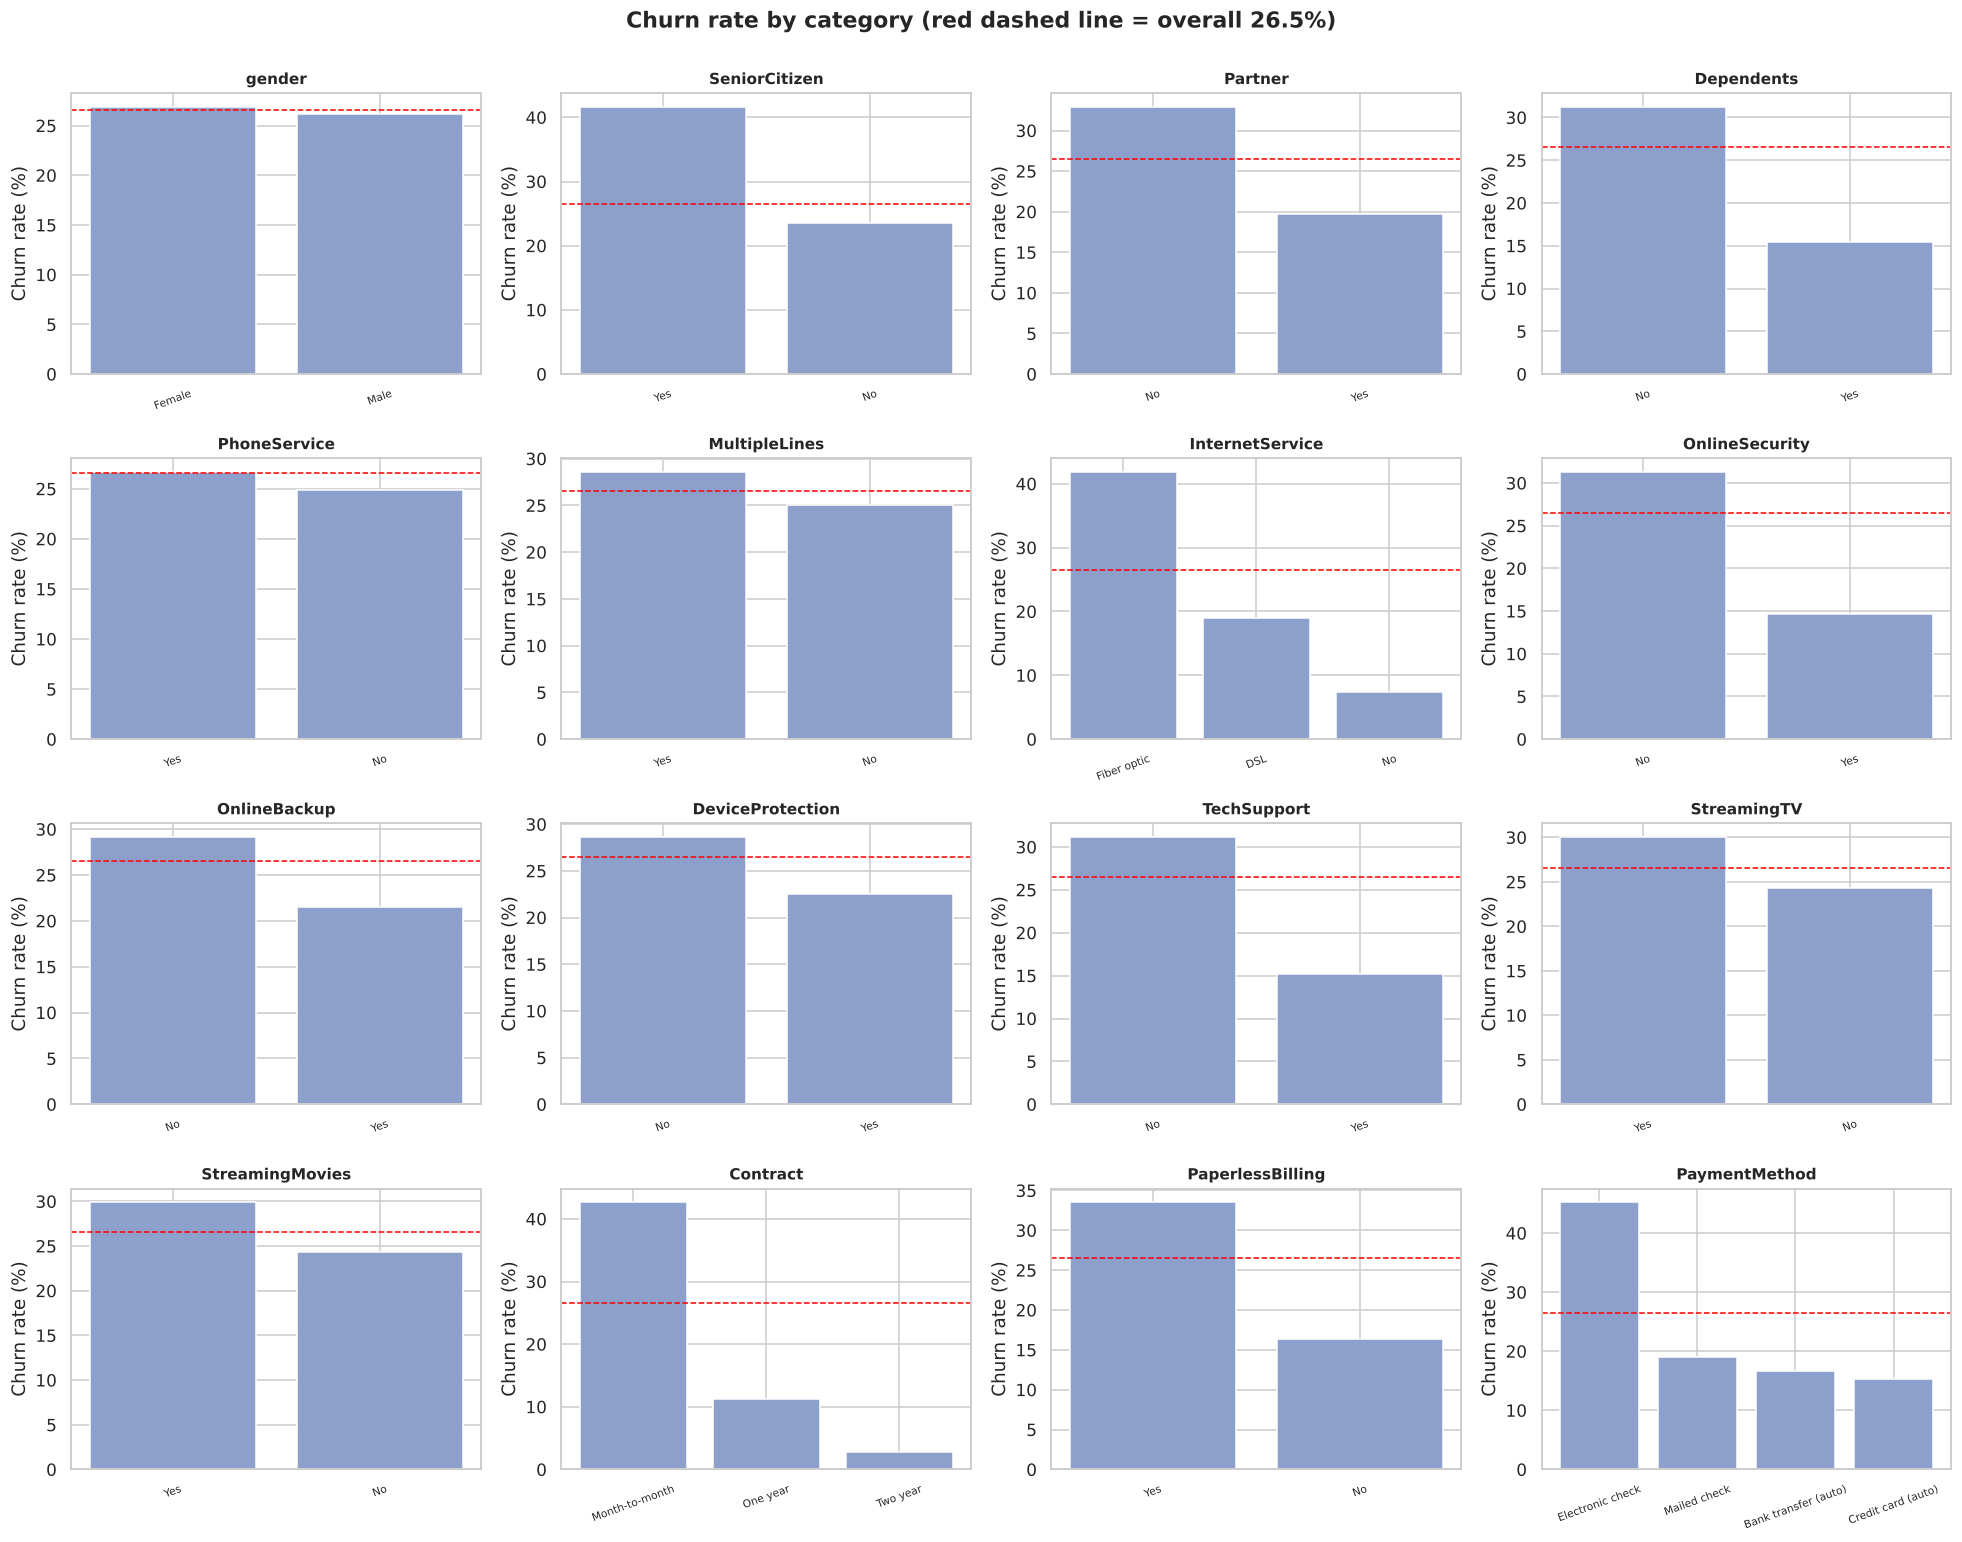

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8 

PaymentMethod
Bank transfer (auto)    16.7
Credit card (auto)      15.2
Electronic check        45.3
Mailed check            19.1 

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4 



In [4]:
# --- 1.3 Class balance and churn rate by category (Figure 1 in the report) -----
churn_rate = df["Churn_flag"].mean()
print(f"Churned: {df['Churn_flag'].sum():,} of {len(df):,} ({churn_rate:.1%}), about {(1-churn_rate)/churn_rate:.1f} to 1 imbalance")

cat_eda = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
           "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
           "Contract", "PaperlessBilling", "PaymentMethod"]
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, c in zip(axes.ravel(), cat_eda):
    r = df.groupby(c)["Churn_flag"].mean().sort_values(ascending=False) * 100
    ax.bar(r.index.astype(str), r.values, color="#8da0cb")
    ax.axhline(churn_rate * 100, color="red", ls="--", lw=1)
    ax.set_title(c, fontsize=10); ax.set_ylabel("Churn rate (%)"); ax.tick_params(axis="x", labelsize=7, rotation=20)
plt.suptitle("Churn rate by category (red dashed line = overall 26.5%)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.savefig("figures/eda_churn_by_category.png", bbox_inches="tight"); plt.show()

for c in ["Contract", "PaymentMethod", "InternetService"]:
    print((df.groupby(c)["Churn_flag"].mean() * 100).round(1).to_string(), "\n")

_tenure_band
0-6      52.9
7-12     35.9
13-24    28.7
25-48    20.4
49-60    14.4
61-72     6.6

Share of all churners in their first 6 months: 41.9%

Correlations among numeric attributes:
                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


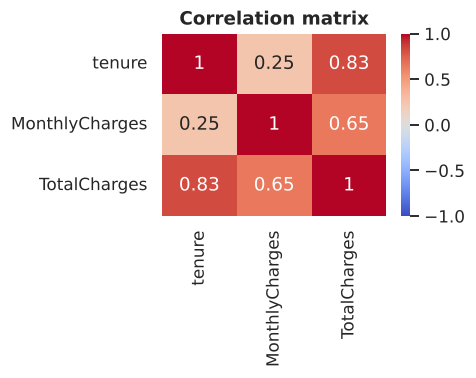

In [5]:
# --- 1.4 Tenure and correlation findings ----------------------------------------
df["_tenure_band"] = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 60, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-60", "61-72"])
print((df.groupby("_tenure_band", observed=True)["Churn_flag"].mean() * 100).round(1).to_string())
print(f"\nShare of all churners in their first 6 months: {(df.loc[df.Churn_flag == 1, 'tenure'] <= 6).mean():.1%}")
df = df.drop(columns="_tenure_band")

num = df[["tenure", "MonthlyCharges", "TotalCharges"]]
print("\nCorrelations among numeric attributes:"); print(num.corr().round(2))
fig, ax = plt.subplots(figsize=(4.5, 3.6)); sns.heatmap(num.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix"); plt.tight_layout(); plt.savefig("figures/eda_correlation.png", bbox_inches="tight"); plt.show()

---
# Part 2 – Feature Engineering and Regression (Deliverable 2)

## 1. Problem Definition

**Outcome variable: `TotalCharges`**, the total revenue a customer has generated over their relationship with the company
(a "customer value to date" measure).

**Business question:** *Given a customer's profile, contract, services and tenure, how much revenue have they generated?*
An accurate revenue model is useful for:
- estimating the value of customer segments and the revenue at risk when customers churn;
- forecasting revenue for new customers as their tenure grows;
- detecting billing anomalies (large residuals mean a bill that does not match the customer's plan).

**Predictors:** demographics, tenure, contract, billing/payment and the nine service columns.

**Excluded to prevent data leakage:**
- `MonthlyCharges`: TotalCharges is essentially tenure × MonthlyCharges, so including it would let the model reproduce the
  answer from a near-copy of the target. Without it, the model must *learn* what each service costs from the service columns.
- `Churn` / `Churn_flag`: churn status is an outcome observed at the same time as the target, not a driver of past revenue.

Deliverable 1 showed that `TotalCharges` is right-skewed (skew 0.96), strongly correlated with `tenure` (r = 0.83),
and that the predictors are correlated with each other. That motivates the feature engineering and regularisation used below.

## 2. Quick look at the cleaned data

In [6]:
print("Shape:", df.shape, "| Missing values:", int(df.isnull().sum().sum()))

Shape: (7043, 21) | Missing values: 0


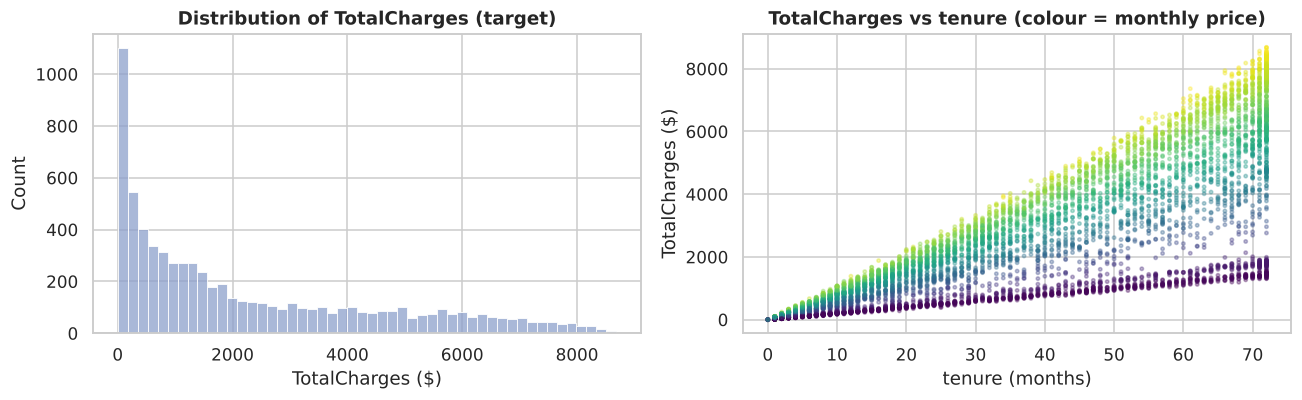

,count,mean,std,min,25%,50%,75%,max
TotalCharges,7043.0,2279.73,2266.79,0.0,398.55,1394.55,3786.6,8684.8


In [7]:
# --- Quick look at the target variable ---------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(df["TotalCharges"], bins=50, ax=ax[0], color="#8da0cb")
ax[0].set(title="Distribution of TotalCharges (target)", xlabel="TotalCharges ($)")
ax[1].scatter(df["tenure"], df["TotalCharges"], s=5, alpha=.35, c=df["MonthlyCharges"], cmap="viridis")
ax[1].set(title="TotalCharges vs tenure (colour = monthly price)", xlabel="tenure (months)", ylabel="TotalCharges ($)")
plt.tight_layout(); plt.savefig("figures/target_overview.png", bbox_inches="tight"); plt.show()
df["TotalCharges"].describe().round(2).to_frame().T

The right-hand plot shows the key structure: **TotalCharges grows linearly with tenure, but the slope depends on the
customer's plan** (more expensive service bundles give steeper lines). A plain linear model can only fit *one* slope for
tenure, so it will struggle. The feature engineering below targets exactly this.

### 2.1 Baseline feature set (raw cleaned features)

In [8]:
TARGET = "TotalCharges"
LEAKY = ["MonthlyCharges", "Churn", "Churn_flag"]   # excluded (see Section 1)

# Categorical columns to one-hot encode. drop_first=True avoids the "dummy variable trap"
# (perfect collinearity between a full set of dummies and the intercept).
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
            "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
            "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

X_base = pd.get_dummies(df.drop(columns=[TARGET] + LEAKY), columns=cat_cols, drop_first=True, dtype=float)
y = df[TARGET].values

print("Baseline feature matrix:", X_base.shape)
list(X_base.columns)

Baseline feature matrix: (7043, 21)


['tenure',
 'gender_Male',
 'SeniorCitizen_Yes',
 'Partner_Yes',
 'Dependents_Yes',
 'PhoneService_Yes',
 'MultipleLines_Yes',
 'InternetService_Fiber optic',
 'InternetService_No',
 'OnlineSecurity_Yes',
 'OnlineBackup_Yes',
 'DeviceProtection_Yes',
 'TechSupport_Yes',
 'StreamingTV_Yes',
 'StreamingMovies_Yes',
 'Contract_One year',
 'Contract_Two year',
 'PaperlessBilling_Yes',
 'PaymentMethod_Credit card (auto)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check']

## 3. Feature Engineering

Each new feature comes from a specific observation in Deliverable 1 or from the structure of the target:

| New feature(s) | Reasoning |
|---|---|
| **`tenure × <service>`** interactions (for every service, contract, billing and payment dummy) | Revenue ≈ months × monthly price, and the monthly price is the sum of the services held. Multiplying tenure by each service indicator lets a *linear* model learn "dollars per month for each service", which turns the multiplicative relationship into an additive one. |
| `num_addons` (0–6) | Count of internet add-ons (security, backup, protection, support, TV, movies). Summarises how "full" the bundle is; Deliverable 1 showed it relates strongly to churn and spend. |
| `num_services` | Total services held, including phone, multiple lines and internet. |
| `tenure × num_addons` | Lets revenue accumulate faster for richer bundles. |
| `auto_payment` | 1 if paying by automatic bank transfer or credit card. Deliverable 1 found payment method matters. |
| `has_family` | 1 if the customer has a partner **or** dependents (combines two related demographics). |
| `contract_months` | Ordinal contract length (1, 12, 24), which keeps the natural ordering of contract types. |
| `tenure_sq` | Squared tenure, to capture any curvature (for example price increases over time). |

Features that use `MonthlyCharges` or `TotalCharges` (such as average monthly spend) were **deliberately not created**,
because they would leak the target.

In [9]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    """Build the engineered feature matrix from the cleaned DataFrame.
    Uses only predictor columns, never the target or leaky columns."""
    X = pd.get_dummies(data.drop(columns=[TARGET] + LEAKY), columns=cat_cols, drop_first=True, dtype=float)

    addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
    # --- Aggregate / summary features -----------------------------------------
    X["num_addons"] = (data[addon_cols] == "Yes").sum(axis=1)
    X["num_services"] = (X["num_addons"]
                         + (data["PhoneService"] == "Yes").astype(int)
                         + (data["MultipleLines"] == "Yes").astype(int)
                         + (data["InternetService"] != "No").astype(int))
    X["auto_payment"] = data["PaymentMethod"].str.contains("auto").astype(int)
    X["has_family"] = ((data["Partner"] == "Yes") | (data["Dependents"] == "Yes")).astype(int)
    X["contract_months"] = data["Contract"].map({"Month-to-month": 1, "One year": 12, "Two year": 24})
    X["tenure_sq"] = data["tenure"] ** 2

    # --- Interaction features: tenure x each service / account indicator ---------
    # (demographic dummies are interacted too, so Lasso can show whether they matter)
    interact_cols = [c for c in X.columns if c not in ("tenure", "tenure_sq", "contract_months")]
    for c in interact_cols:
        X[f"tenure_x_{c}"] = X["tenure"] * X[c]
    return X

X_eng = engineer_features(df)
print("Baseline features  :", X_base.shape[1])
print("Engineered features:", X_eng.shape[1])
X_eng.filter(regex="^(num_|auto_|has_|contract_months|tenure_sq|tenure_x_InternetService)").head()

Baseline features  : 21
Engineered features: 51


,num_addons,num_services,auto_payment,has_family,contract_months,tenure_sq,tenure_x_InternetService_Fiber optic,tenure_x_InternetService_No
0,1,2,0,1,1,1,0.0,0.0
1,2,4,0,0,12,1156,0.0,0.0
2,2,4,0,0,1,4,0.0,0.0
3,3,4,1,0,12,2025,0.0,0.0
4,0,2,0,0,1,4,2.0,0.0


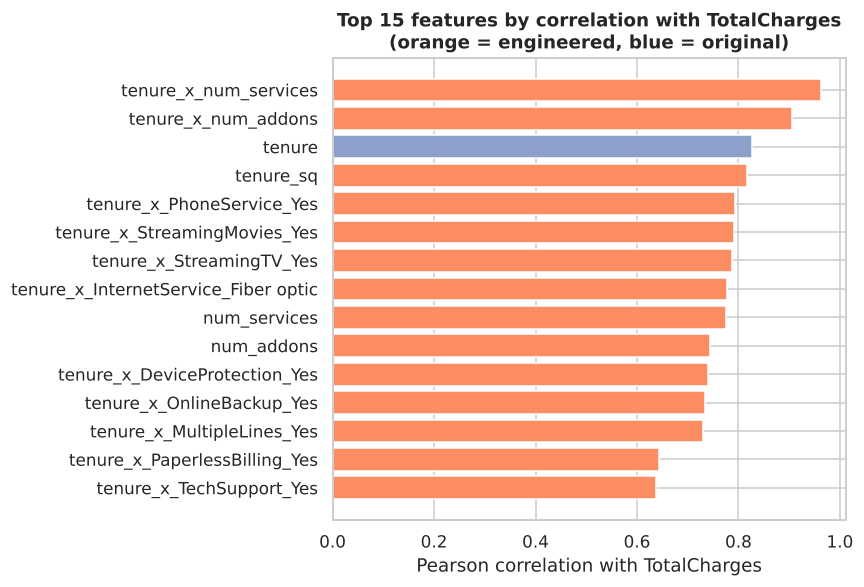

In [10]:
# --- Does feature engineering create features that are more related to the target? ---
corr_new = (X_eng.assign(TotalCharges=y).corr()["TotalCharges"]
            .drop("TotalCharges").sort_values(key=abs, ascending=False).head(15))
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#fc8d62" if c.startswith("tenure_x") or c in ("num_addons", "num_services", "tenure_sq") else "#8da0cb"
          for c in corr_new.index]
ax.barh(corr_new.index[::-1], corr_new.values[::-1], color=colors[::-1])
ax.set(title="Top 15 features by correlation with TotalCharges\n(orange = engineered, blue = original)",
       xlabel="Pearson correlation with TotalCharges")
plt.tight_layout(); plt.savefig("figures/engineered_feature_correlation.png", bbox_inches="tight"); plt.show()

The engineered interaction features are the **most strongly correlated** predictors of revenue. For example
`tenure_x_num_addons` and `tenure_x_InternetService_Fiber optic` each beat `tenure` on its own. This shows early on that feature
engineering should improve model performance.

## 4. Modelling Setup

- **Train/test split (80/20):** the test set is put aside and used **only once** for the final evaluation.
- **10-fold cross-validation** on the training set estimates how well each model generalises and how stable it is across different data subsets.
- **Pipelines** bundle scaling with the model so that the `StandardScaler` is fit **only on the training folds** in every CV iteration. This avoids leaking information from validation folds.
- **Scaling** is essential for Ridge and Lasso: their penalties treat all coefficients equally, so features must be on comparable scales.
- **Hyperparameter tuning:** `RidgeCV` and `LassoCV` choose the regularisation strength α by an inner cross-validation. Run inside the outer 10-fold CV, this gives **nested cross-validation**, an unbiased estimate of tuned-model performance.

In [11]:
# Same row split for both feature sets so the comparison is fair
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.20, random_state=RANDOM_STATE)
Xb_train, Xb_test = X_base.iloc[idx_train], X_base.iloc[idx_test]
Xe_train, Xe_test = X_eng.iloc[idx_train], X_eng.iloc[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

print(f"Training rows: {len(idx_train):,}   Test rows: {len(idx_test):,}")
print(f"Mean TotalCharges  train: ${y_train.mean():,.2f}   test: ${y_test.mean():,.2f}")

# 10-fold CV with shuffling (rows are not ordered in time, so shuffling is appropriate)
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
ALPHAS = np.logspace(-3, 3, 50)   # candidate regularisation strengths

Training rows: 5,634   Test rows: 1,409
Mean TotalCharges  train: $2,287.09   test: $2,250.33


## 5. Regression Models

| # | Model | Features | Purpose |
|---|---|---|---|
| 1 | **Linear Regression (baseline)** | Baseline (21) | Ordinary least squares on the raw cleaned features: the reference point |
| 2 | **Multiple Linear Regression (engineered)** | Engineered | Isolates the effect of feature engineering (same algorithm, better features) |
| 3 | **Ridge Regression** (L2) | Engineered | Shrinks coefficients to handle the strong multicollinearity created by the interactions |
| 4 | **Lasso Regression** (L1) | Engineered | Shrinks *and* sets unhelpful coefficients to exactly zero, which performs automatic feature selection |
| 5 | **Random Forest** (benchmark) | Baseline | A non-linear model that learns interactions on its own, to check whether manual engineering is competitive |

In [12]:
# Each entry: (pipeline, which feature set it uses)
models = {
    "Linear (baseline)": (Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]), "base"),
    "Linear (engineered)": (Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]), "eng"),
    "Ridge (engineered)": (Pipeline([("scaler", StandardScaler()), ("model", RidgeCV(alphas=ALPHAS))]), "eng"),
    "Lasso (engineered)": (Pipeline([("scaler", StandardScaler()),
                                     ("model", LassoCV(alphas=ALPHAS, cv=5, max_iter=50000, random_state=RANDOM_STATE))]), "eng"),
    "Random Forest (baseline)": (Pipeline([("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                                          n_jobs=-1, random_state=RANDOM_STATE))]), "base"),
}
feature_sets = {"base": (Xb_train, Xb_test), "eng": (Xe_train, Xe_test)}

### 5.1 Cross-validation on the training set

In [13]:
scoring = {"r2": "r2", "mse": "neg_mean_squared_error", "rmse": "neg_root_mean_squared_error",
           "mae": "neg_mean_absolute_error"}
cv_results, cv_fold_scores = {}, {}

for name, (pipe, fs) in models.items():
    X_tr, _ = feature_sets[fs]
    t0 = time.time()
    res = cross_validate(pipe, X_tr, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results[name] = {
        "CV R² (mean)": res["test_r2"].mean(),
        "CV R² (std)": res["test_r2"].std(),
        "CV MSE": -res["test_mse"].mean(),
        "CV RMSE": -res["test_rmse"].mean(),
        "CV RMSE (std)": res["test_rmse"].std(),
        "CV MAE": -res["test_mae"].mean(),
        "Fit time (s)": time.time() - t0,
    }
    cv_fold_scores[name] = {"R²": res["test_r2"], "RMSE": -res["test_rmse"]}
    print(f"{name:<26} R² = {res['test_r2'].mean():.4f} ± {res['test_r2'].std():.4f}   "
          f"RMSE = ${-res['test_rmse'].mean():,.2f}")

cv_df = pd.DataFrame(cv_results).T
cv_df.style.format({"CV R² (mean)": "{:.4f}", "CV R² (std)": "{:.4f}", "CV MSE": "{:,.0f}",
                    "CV RMSE": "${:,.2f}", "CV RMSE (std)": "{:,.2f}", "CV MAE": "${:,.2f}", "Fit time (s)": "{:.1f}"})

Linear (baseline)          R² = 0.9068 ± 0.0042   RMSE = $689.86


Linear (engineered)        R² = 0.9987 ± 0.0001   RMSE = $81.85


Ridge (engineered)         R² = 0.9987 ± 0.0001   RMSE = $81.85


Lasso (engineered)         R² = 0.9987 ± 0.0001   RMSE = $81.66


Random Forest (baseline)   R² = 0.9956 ± 0.0004   RMSE = $149.49


,CV R² (mean),CV R² (std),CV MSE,CV RMSE,CV RMSE (std),CV MAE,Fit time (s)
Linear (baseline),0.9068,0.0042,"476,068",$689.86,12.71,$555.45,0.1
Linear (engineered),0.9987,0.0001,"6,709",$81.85,3.17,$53.93,0.2
Ridge (engineered),0.9987,0.0001,"6,709",$81.85,3.16,$53.93,1.1
Lasso (engineered),0.9987,0.0001,"6,678",$81.66,3.16,$53.63,4.2
Random Forest (baseline),0.9956,0.0004,"22,399",$149.49,7.22,$94.57,30.1


### 5.2 Final fit and evaluation on the held-out test set

In [14]:
test_results, test_preds, fitted = {}, {}, {}
for name, (pipe, fs) in models.items():
    X_tr, X_te = feature_sets[fs]
    pipe.fit(X_tr, y_train)                       # fit on the full training set
    pred = pipe.predict(X_te)                     # predict unseen test data
    fitted[name], test_preds[name] = pipe, pred
    test_results[name] = {
        "Test R²": r2_score(y_test, pred),
        "Test MSE": mean_squared_error(y_test, pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test MAE": mean_absolute_error(y_test, pred),
    }

# Selected hyperparameters for the regularised models
ridge_alpha = fitted["Ridge (engineered)"].named_steps["model"].alpha_
lasso_alpha = fitted["Lasso (engineered)"].named_steps["model"].alpha_
print(f"Ridge selected alpha = {ridge_alpha:.4f}")
print(f"Lasso selected alpha = {lasso_alpha:.4f}")

test_df = pd.DataFrame(test_results).T
test_df.style.format({"Test R²": "{:.4f}", "Test MSE": "{:,.0f}", "Test RMSE": "${:,.2f}", "Test MAE": "${:,.2f}"})

Ridge selected alpha = 0.3728
Lasso selected alpha = 0.8685


,Test R²,Test MSE,Test RMSE,Test MAE
Linear (baseline),0.9043,"497,639",$705.44,$571.20
Linear (engineered),0.9986,"7,279",$85.32,$54.53
Ridge (engineered),0.9986,"7,279",$85.32,$54.54
Lasso (engineered),0.9986,"7,226",$85.00,$54.20
Random Forest (baseline),0.9953,"24,248",$155.72,$94.67


## 6. Model Evaluation: Combined Comparison

In [15]:
summary = cv_df[["CV R² (mean)", "CV R² (std)", "CV RMSE", "CV MAE"]].join(test_df)
summary["RMSE gap (test − CV)"] = summary["Test RMSE"] - summary["CV RMSE"]
summary = summary.sort_values("Test RMSE")
summary.to_csv("model_comparison_results.csv")
summary.style.format({"CV R² (mean)": "{:.4f}", "CV R² (std)": "{:.4f}", "CV RMSE": "${:,.2f}", "CV MAE": "${:,.2f}",
                      "Test R²": "{:.4f}", "Test MSE": "{:,.0f}", "Test RMSE": "${:,.2f}", "Test MAE": "${:,.2f}",
                      "RMSE gap (test − CV)": "{:+,.2f}"}) \
    .highlight_min(subset=["CV RMSE", "Test RMSE", "Test MAE"], color="#c7e9c0") \
    .highlight_max(subset=["CV R² (mean)", "Test R²"], color="#c7e9c0")

,CV R² (mean),CV R² (std),CV RMSE,CV MAE,Test R²,Test MSE,Test RMSE,Test MAE,RMSE gap (test − CV)
Lasso (engineered),0.9987,0.0001,$81.66,$53.63,0.9986,"7,226",$85.00,$54.20,+3.34
Linear (engineered),0.9987,0.0001,$81.85,$53.93,0.9986,"7,279",$85.32,$54.53,+3.47
Ridge (engineered),0.9987,0.0001,$81.85,$53.93,0.9986,"7,279",$85.32,$54.54,+3.47
Random Forest (baseline),0.9956,0.0004,$149.49,$94.57,0.9953,"24,248",$155.72,$94.67,+6.23
Linear (baseline),0.9068,0.0042,$689.86,$555.45,0.9043,"497,639",$705.44,$571.20,+15.58


In [16]:
base_rmse = summary.loc["Linear (baseline)", "Test RMSE"]
eng_rmse = summary.loc["Linear (engineered)", "Test RMSE"]
print(f"Feature engineering reduced the linear model's test RMSE from ${base_rmse:,.2f} to ${eng_rmse:,.2f} "
      f"({(1 - eng_rmse / base_rmse):.1%} reduction).")
print(f"Test R² improved from {summary.loc['Linear (baseline)', 'Test R²']:.4f} "
      f"to {summary.loc['Linear (engineered)', 'Test R²']:.4f}.")
print(f"Mean TotalCharges is ${y.mean():,.2f}; the best model's MAE is "
      f"{summary['Test MAE'].min() / y.mean():.1%} of the average bill.")

Feature engineering reduced the linear model's test RMSE from $705.44 to $85.32 (87.9% reduction).
Test R² improved from 0.9043 to 0.9986.
Mean TotalCharges is $2,279.73; the best model's MAE is 2.4% of the average bill.


## 7. Visual Comparison of Model Performance

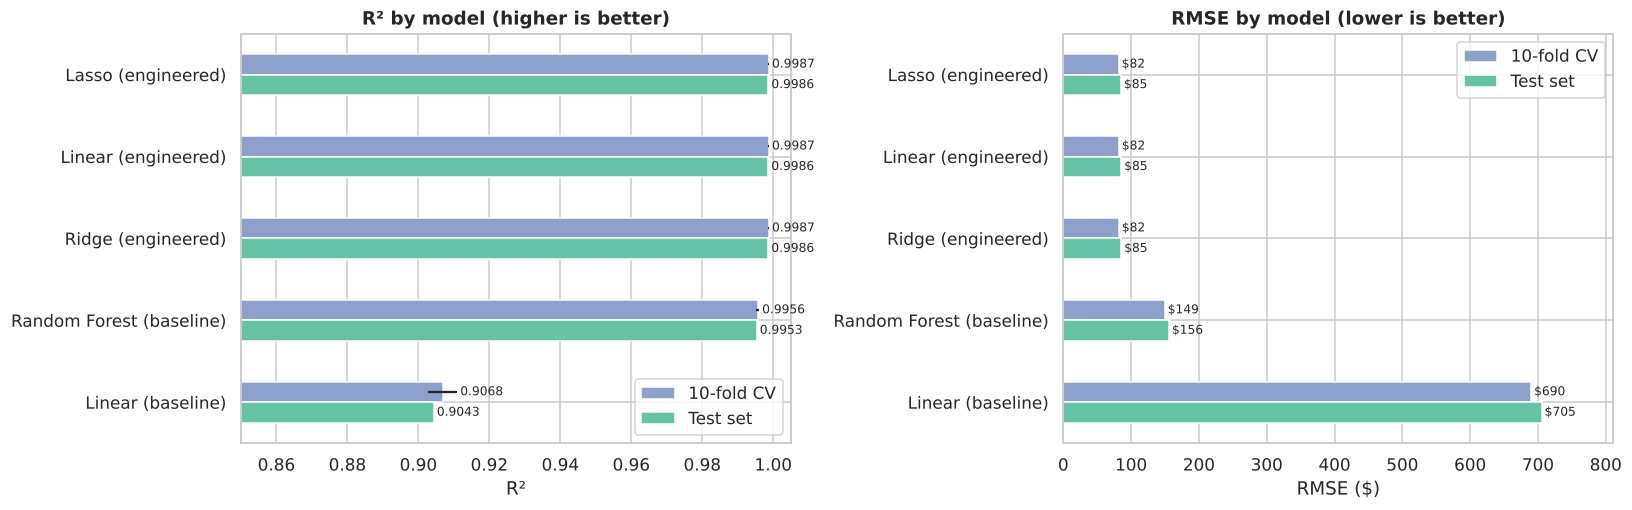

In [17]:
# --- 7.1 Bar charts of R² and RMSE (CV vs test) -----------------------------------
order = summary.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

r2_plot = pd.DataFrame({"10-fold CV": summary["CV R² (mean)"], "Test set": summary["Test R²"]}).loc[order]
r2_plot.plot.barh(ax=axes[0], color=["#8da0cb", "#66c2a5"], xerr=pd.DataFrame(
    {"10-fold CV": summary["CV R² (std)"], "Test set": 0}).loc[order])
axes[0].set(title="R² by model (higher is better)", xlabel="R²", xlim=(0.85, 1.005))
for c in axes[0].containers:
    if hasattr(c, "datavalues"):
        axes[0].bar_label(c, fmt="%.4f", fontsize=8, padding=2)
axes[0].invert_yaxis()

rmse_plot = pd.DataFrame({"10-fold CV": summary["CV RMSE"], "Test set": summary["Test RMSE"]}).loc[order]
rmse_plot.plot.barh(ax=axes[1], color=["#8da0cb", "#66c2a5"])
axes[1].set(title="RMSE by model (lower is better)", xlabel="RMSE ($)")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="$%.0f", fontsize=8, padding=2)
axes[1].invert_yaxis()
axes[1].set_xlim(0, rmse_plot.values.max() * 1.15)
plt.tight_layout(); plt.savefig("figures/model_comparison_bars.png", bbox_inches="tight"); plt.show()

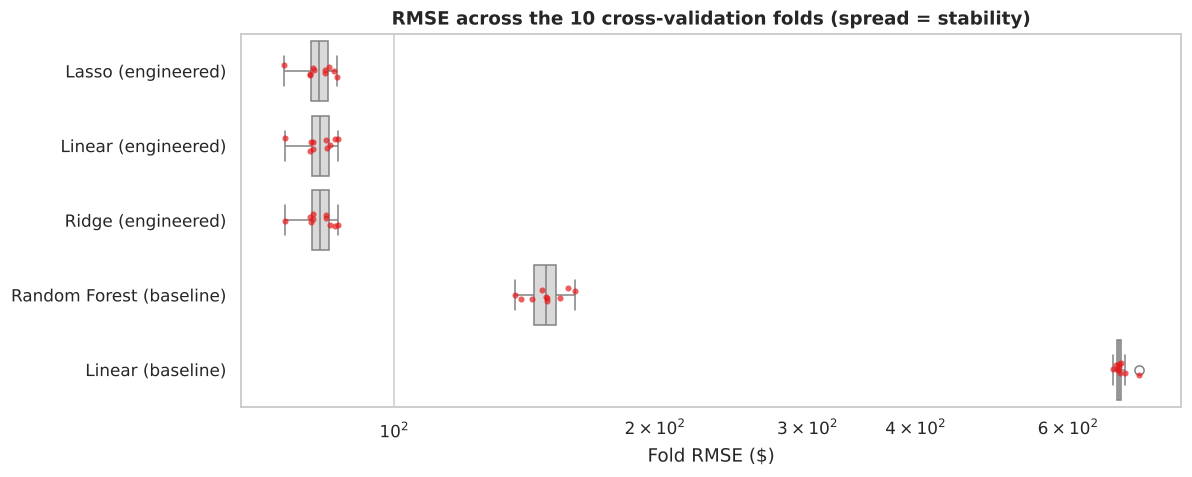

In [18]:
# --- 7.2 Distribution of RMSE across the 10 CV folds (stability) ----------------------
fold_df = pd.DataFrame({n: s["RMSE"] for n, s in cv_fold_scores.items()}).melt(var_name="Model", value_name="RMSE")
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=fold_df, x="RMSE", y="Model", order=order, ax=ax, color="#d9d9d9")
sns.stripplot(data=fold_df, x="RMSE", y="Model", order=order, ax=ax, color="#e41a1c", size=4, alpha=.7)
ax.set(title="RMSE across the 10 cross-validation folds (spread = stability)", xlabel="Fold RMSE ($)", ylabel="")
ax.set_xscale("log")
plt.tight_layout(); plt.savefig("figures/cv_fold_rmse_boxplot.png", bbox_inches="tight"); plt.show()

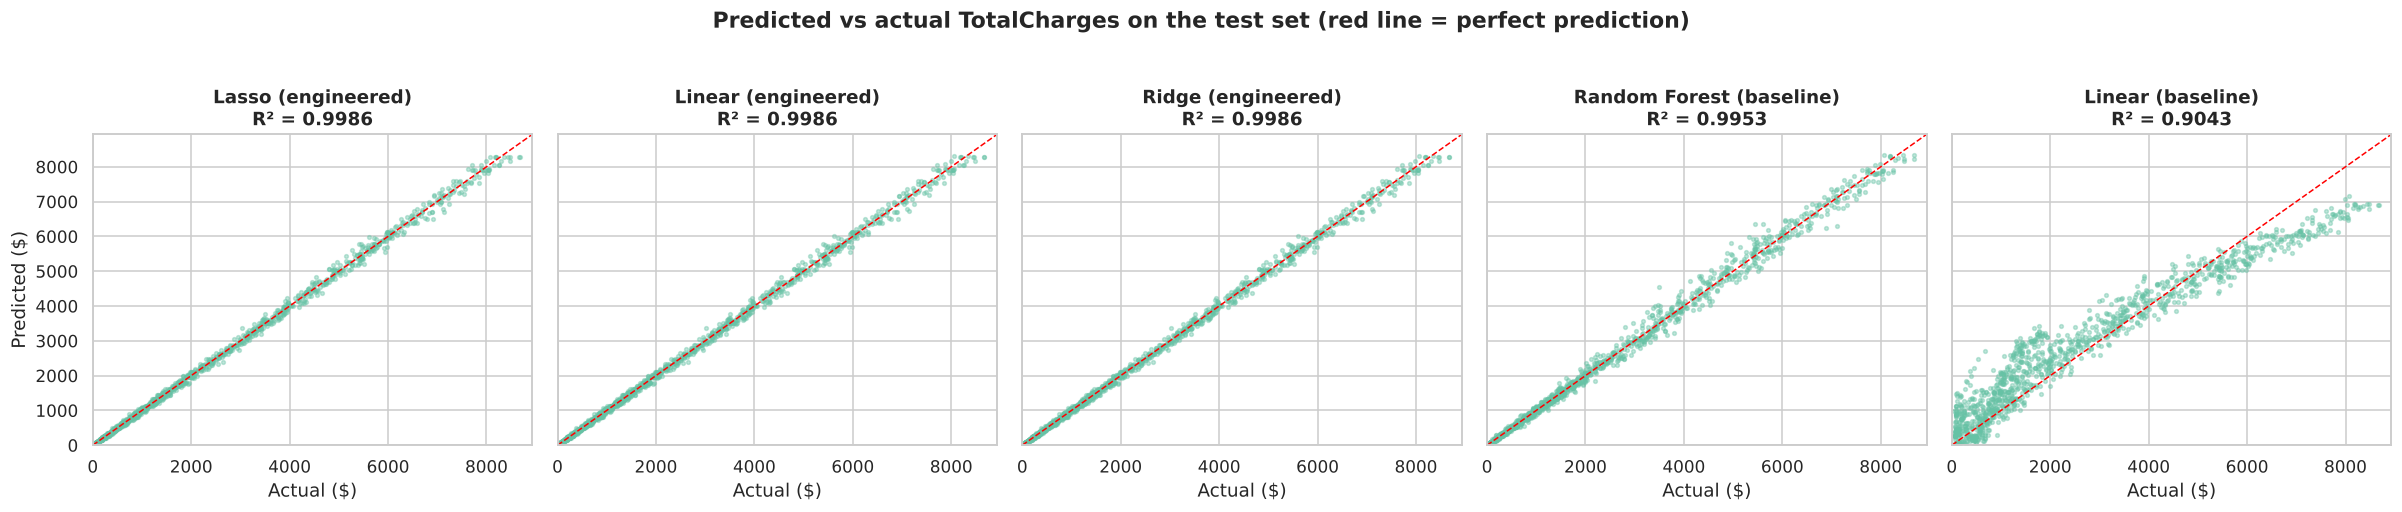

In [19]:
# --- 7.3 Predicted vs actual on the test set -----------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)
lim = [0, max(y_test.max(), max(p.max() for p in test_preds.values())) * 1.03]
for ax, name in zip(axes, order):
    ax.scatter(y_test, test_preds[name], s=6, alpha=.4)
    ax.plot(lim, lim, "r--", lw=1)
    ax.set(title=f"{name}\nR² = {summary.loc[name, 'Test R²']:.4f}", xlabel="Actual ($)", xlim=lim, ylim=lim)
axes[0].set_ylabel("Predicted ($)")
fig.suptitle("Predicted vs actual TotalCharges on the test set (red line = perfect prediction)", weight="bold", y=1.03)
plt.tight_layout(); plt.savefig("figures/predicted_vs_actual.png", bbox_inches="tight"); plt.show()

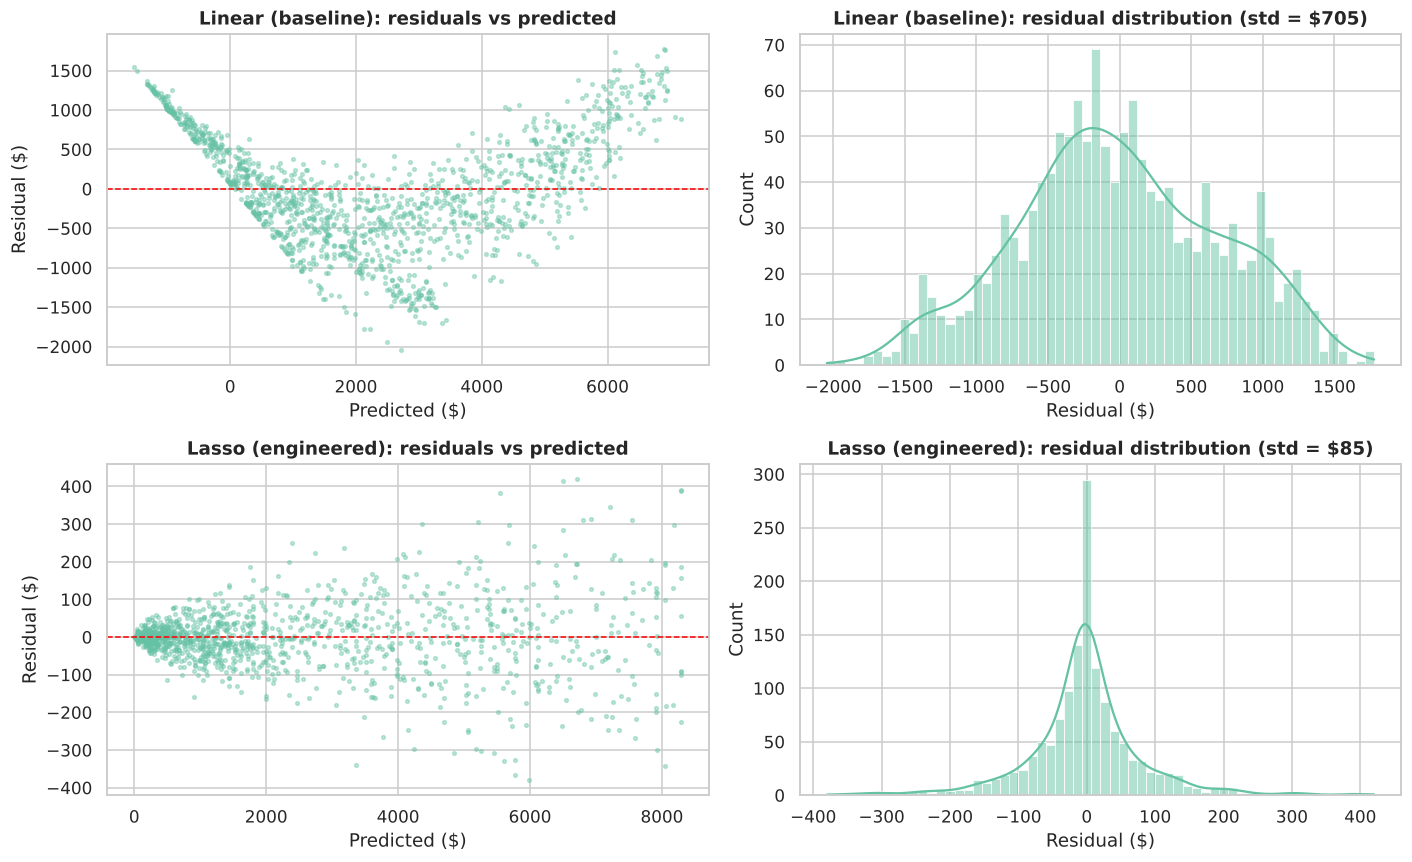

In [20]:
# --- 7.4 Residual analysis: baseline vs best linear model ----------------------------
best_name = summary.index[0]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, name in enumerate(["Linear (baseline)", best_name]):
    resid = y_test - test_preds[name]
    axes[row, 0].scatter(test_preds[name], resid, s=6, alpha=.4)
    axes[row, 0].axhline(0, color="red", ls="--", lw=1)
    axes[row, 0].set(title=f"{name}: residuals vs predicted", xlabel="Predicted ($)", ylabel="Residual ($)")
    sns.histplot(resid, bins=60, ax=axes[row, 1], kde=True)
    axes[row, 1].set(title=f"{name}: residual distribution (std = ${resid.std():,.0f})", xlabel="Residual ($)")
plt.tight_layout(); plt.savefig("figures/residual_analysis.png", bbox_inches="tight"); plt.show()

**Reading the residual plots:** the baseline model's residuals form a clear **U-shape**. It even predicts *negative* revenue
for some new customers, under-predicts at both ends of the range and over-predicts in the middle. This systematic pattern shows the
model is missing the tenure × price structure (its residual standard deviation is about \$705). After feature engineering the residuals are about
**8× smaller, centred on zero and without a curve**. Their spread grows slightly for high-value customers, which is expected: the longer
a customer stays, the more price changes accumulate on their bill (the same deviations found in Deliverable 1's consistency check).

### 7.5 Hyperparameter tuning: effect of the regularisation strength α

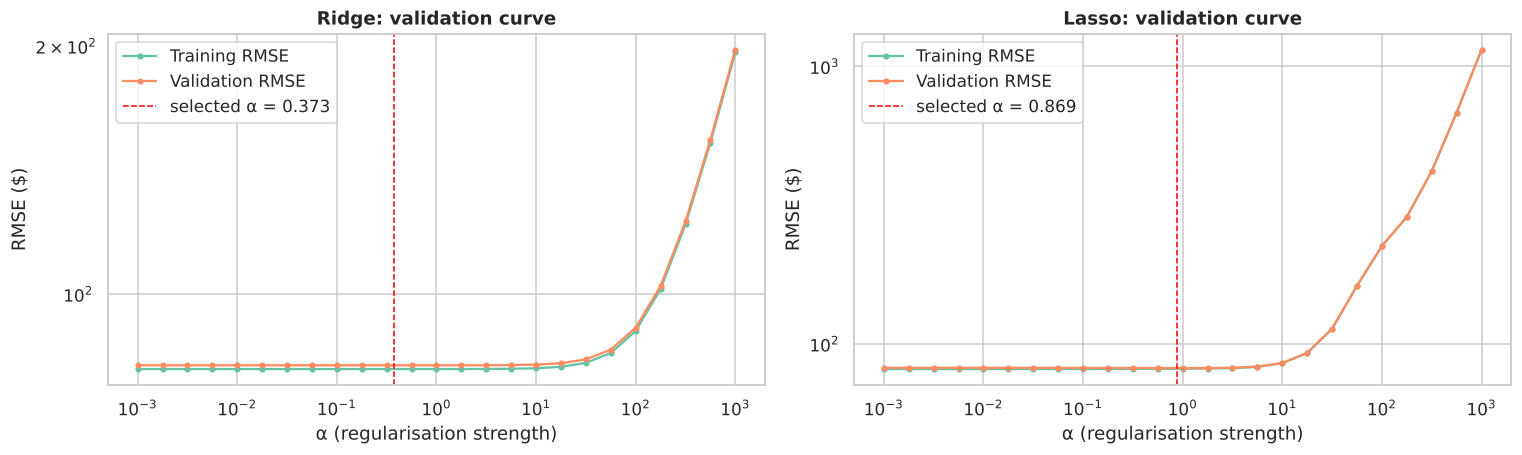

In [21]:
# Validation curves: CV RMSE as a function of alpha for Ridge and Lasso on the engineered features
alpha_grid = np.logspace(-3, 3, 25)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for ax, (label, est, chosen) in zip(axes, [("Ridge", Ridge(), ridge_alpha),
                                           ("Lasso", Lasso(max_iter=50000), lasso_alpha)]):
    pipe = Pipeline([("scaler", StandardScaler()), ("model", est)])
    tr, va = validation_curve(pipe, Xe_train, y_train, param_name="model__alpha", param_range=alpha_grid,
                              cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    ax.plot(alpha_grid, -tr.mean(1), "o-", ms=3, label="Training RMSE")
    ax.plot(alpha_grid, -va.mean(1), "o-", ms=3, label="Validation RMSE")
    ax.axvline(chosen, color="red", ls="--", lw=1, label=f"selected α = {chosen:.3g}")
    ax.set(xscale="log", yscale="log", title=f"{label}: validation curve", xlabel="α (regularisation strength)",
           ylabel="RMSE ($)")
    ax.legend()
plt.tight_layout(); plt.savefig("figures/alpha_validation_curves.png", bbox_inches="tight"); plt.show()

Small α values give the lowest error: once the right interaction features exist, the relationship is close to linear, so
little shrinkage is needed. As α grows, the penalty shrinks real price effects towards zero and error rises sharply (underfitting).
Training and validation curves lie almost on top of each other, which means **no overfitting**, even with many features.

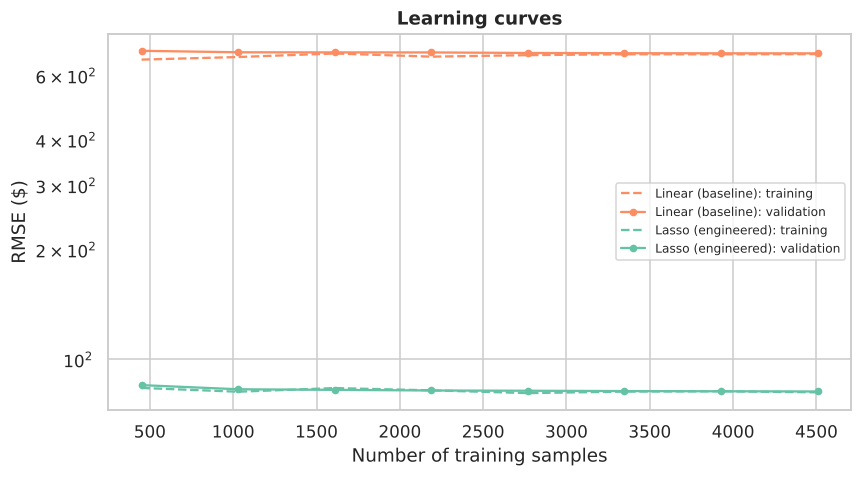

In [22]:
# --- 7.6 Learning curves: how performance changes with more training data -------------
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, color in [("Linear (baseline)", "#fc8d62"), ("Lasso (engineered)", "#66c2a5")]:
    pipe, fs = models[name]
    X_tr, _ = feature_sets[fs]
    sizes, tr, va = learning_curve(pipe, X_tr, y_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                                   train_sizes=np.linspace(.1, 1, 8), scoring="neg_root_mean_squared_error", n_jobs=-1)
    ax.plot(sizes, -tr.mean(1), "--", color=color, label=f"{name}: training")
    ax.plot(sizes, -va.mean(1), "-o", ms=4, color=color, label=f"{name}: validation")
ax.set(title="Learning curves", xlabel="Number of training samples", ylabel="RMSE ($)", yscale="log")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/learning_curves.png", bbox_inches="tight"); plt.show()

The baseline model's training and validation errors converge at a **high** value (about \$690): it suffers from **high bias** (underfitting),
and more data would not help. Only better features fix that. The engineered Lasso model converges at a much lower error, and its
curves meet early, so the model **generalises well** even from a fraction of the data.

## 8. Model Interpretation

Lasso kept 17 of 51 engineered features and set 34 coefficients to exactly zero.


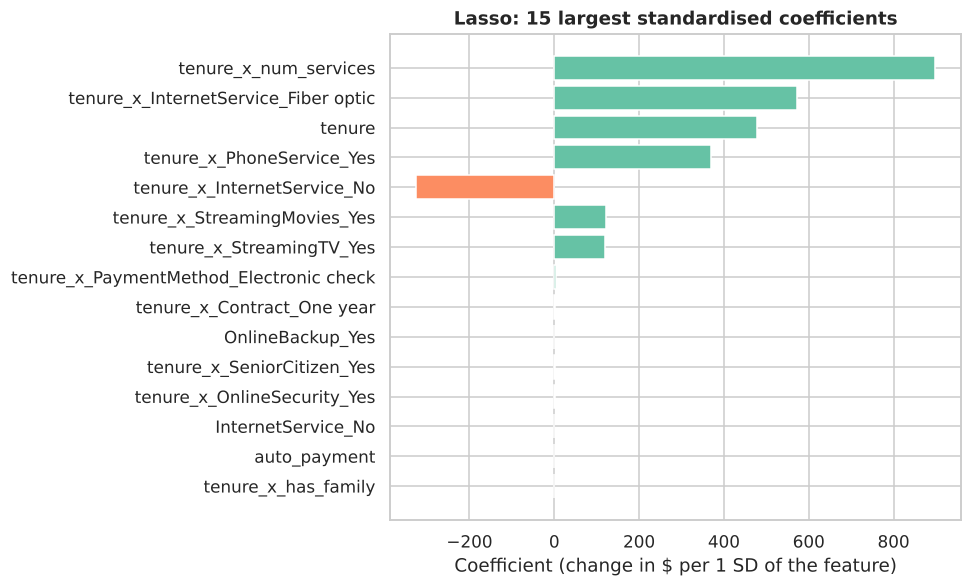


Features removed by Lasso (coefficient = 0):
['gender_Male', 'SeniorCitizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'OnlineSecurity_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (auto)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'num_addons', 'num_services', 'has_family', 'contract_months', 'tenure_sq', 'tenure_x_gender_Male', 'tenure_x_Partner_Yes', 'tenure_x_Dependents_Yes', 'tenure_x_MultipleLines_Yes', 'tenure_x_OnlineBackup_Yes', 'tenure_x_DeviceProtection_Yes', 'tenure_x_TechSupport_Yes', 'tenure_x_Contract_Two year', 'tenure_x_PaymentMethod_Credit card (auto)', 'tenure_x_num_addons', 'tenure_x_auto_payment']

The 7 largest coefficients account for 99.6% of the total absolute coefficient weight.


In [23]:
# --- 8.1 Lasso feature selection ---------------------------------------------------
lasso = fitted["Lasso (engineered)"].named_steps["model"]
coef = pd.Series(lasso.coef_, index=X_eng.columns)
n_zero = int((coef == 0).sum())
print(f"Lasso kept {len(coef) - n_zero} of {len(coef)} engineered features and set {n_zero} coefficients to exactly zero.")

top = coef[coef != 0].sort_values(key=abs, ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index[::-1], top.values[::-1], color=["#66c2a5" if v > 0 else "#fc8d62" for v in top.values[::-1]])
ax.set(title="Lasso: 15 largest standardised coefficients", xlabel="Coefficient (change in $ per 1 SD of the feature)")
plt.tight_layout(); plt.savefig("figures/lasso_top_coefficients.png", bbox_inches="tight"); plt.show()

print("\nFeatures removed by Lasso (coefficient = 0):")
print(coef[coef == 0].index.tolist())
share = (top.abs().head(7).sum() / coef.abs().sum())
print(f"\nThe 7 largest coefficients account for {share:.1%} of the total absolute coefficient weight.")

In [24]:
# --- 8.2 Recovering the price list: what does each service add per month? -------------
# Fit an unscaled OLS on the engineered features: the coefficient on 'tenure_x_<service>' is then
# directly interpretable as the dollars per month that the service adds to accumulated revenue.
ols_raw = LinearRegression().fit(Xe_train, y_train)
raw_coef = pd.Series(ols_raw.coef_, index=X_eng.columns)
price_cols = ["tenure_x_PhoneService_Yes", "tenure_x_MultipleLines_Yes", "tenure_x_InternetService_Fiber optic",
              "tenure_x_InternetService_No", "tenure_x_OnlineSecurity_Yes", "tenure_x_OnlineBackup_Yes",
              "tenure_x_DeviceProtection_Yes", "tenure_x_TechSupport_Yes", "tenure_x_StreamingTV_Yes",
              "tenure_x_StreamingMovies_Yes"]

# Ridge on unscaled features is used for this table because num_addons / tenure_x_num_addons are exact linear
# combinations of the individual add-on columns (perfect multicollinearity). Plain OLS cannot split the effect
# uniquely between them; a tiny ridge penalty gives a stable, unique solution.
from sklearn.linear_model import Ridge as _Ridge
ridge_raw = _Ridge(alpha=1e-3).fit(Xe_train.drop(columns=["num_addons", "tenure_x_num_addons",
                                                           "num_services", "tenure_x_num_services"]), y_train)
rc = pd.Series(ridge_raw.coef_, index=Xe_train.drop(columns=["num_addons", "tenure_x_num_addons",
                                                             "num_services", "tenure_x_num_services"]).columns)
price_table = rc[price_cols].rename(lambda s: s.replace("tenure_x_", "").replace("_Yes", "")).round(2)
price_table.to_frame("Estimated $ per month added").sort_values("Estimated $ per month added")

,Estimated $ per month added
InternetService_No,-24.68
OnlineBackup,4.94
MultipleLines,5.11
DeviceProtection,5.16
OnlineSecurity,5.19
TechSupport,5.23
StreamingTV,9.90
StreamingMovies,9.96
PhoneService,19.86
InternetService_Fiber optic,24.87


The interaction coefficients recover an interpretable **price list** from revenue data alone, without ever seeing
`MonthlyCharges`. Fiber-optic internet is the most expensive component, streaming services each add roughly \$10/month, and
customers with no internet pay far less. This explains *why* the engineered linear model works so well:
**the company's revenue really is additive in services multiplied by tenure**, and the engineered features express exactly that.

In [25]:
# --- 8.3 Sanity check on the pricing structure: MonthlyCharges is almost exactly additive ---
# (Not a modelling target, because it is too easy. It confirms the insight above.)
svc = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
       "TechSupport", "StreamingTV", "StreamingMovies"]
X_svc = pd.get_dummies(df[svc], drop_first=True, dtype=float)
r2_monthly = cross_validate(LinearRegression(), X_svc, df["MonthlyCharges"], cv=cv, scoring="r2")["test_score"].mean()
print(f"Linear regression of MonthlyCharges on the 9 service columns only: 10-fold CV R² = {r2_monthly:.4f}")

Linear regression of MonthlyCharges on the 9 service columns only: 10-fold CV R² = 0.9988


## 9. Extension: Predicting Customer Tenure

Revenue is largely driven by billing rules. A harder and more *behavioural* question is **how long a customer stays** (`tenure`).
The same models are applied, with `TotalCharges` excluded (it would leak tenure), `Churn` excluded (for the same reason as before), and `MonthlyCharges` allowed (a customer's
price is known at any time). This shows how the models behave when the target is driven by human behaviour rather than pricing.

In [26]:
y_ten = df["tenure"].values
X_ten_base = pd.get_dummies(df.drop(columns=["tenure", "TotalCharges", "Churn", "Churn_flag"]), columns=cat_cols,
                            drop_first=True, dtype=float)
# Engineered set for tenure: summary features plus MonthlyCharges interactions with contract / services
X_ten_eng = X_ten_base.copy()
X_ten_eng["num_addons"] = X_eng["num_addons"]
X_ten_eng["auto_payment"] = X_eng["auto_payment"]
X_ten_eng["has_family"] = X_eng["has_family"]
X_ten_eng["contract_months"] = X_eng["contract_months"]
for c in [c for c in X_ten_base.columns if c.startswith(("Contract_", "InternetService_", "PaymentMethod_", "OnlineSecurity_", "TechSupport_"))]:
    X_ten_eng[f"Monthly_x_{c}"] = X_ten_base["MonthlyCharges"] * X_ten_base[c]
X_ten_eng["contract_x_addons"] = X_ten_eng["contract_months"] * X_ten_eng["num_addons"]

ten_models = {
    "Linear (baseline)": (Pipeline([("s", StandardScaler()), ("m", LinearRegression())]), X_ten_base),
    "Linear (engineered)": (Pipeline([("s", StandardScaler()), ("m", LinearRegression())]), X_ten_eng),
    "Ridge (engineered)": (Pipeline([("s", StandardScaler()), ("m", RidgeCV(alphas=ALPHAS))]), X_ten_eng),
    "Lasso (engineered)": (Pipeline([("s", StandardScaler()), ("m", LassoCV(alphas=ALPHAS, cv=5, max_iter=50000))]), X_ten_eng),
    "Random Forest (baseline)": (Pipeline([("m", RandomForestRegressor(300, min_samples_leaf=5, n_jobs=-1,
                                                                        random_state=RANDOM_STATE))]), X_ten_base),
}
ten_rows = {}
for name, (pipe, Xt) in ten_models.items():
    res = cross_validate(pipe, Xt.iloc[idx_train], y_ten[idx_train], cv=cv, n_jobs=-1,
                         scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"})
    pipe.fit(Xt.iloc[idx_train], y_ten[idx_train])
    p = pipe.predict(Xt.iloc[idx_test])
    ten_rows[name] = {"CV R²": res["test_r2"].mean(), "CV RMSE (months)": -res["test_rmse"].mean(),
                      "Test R²": r2_score(y_ten[idx_test], p),
                      "Test RMSE (months)": np.sqrt(mean_squared_error(y_ten[idx_test], p))}
ten_df = pd.DataFrame(ten_rows).T.sort_values("Test RMSE (months)")
ten_df.to_csv("tenure_model_results.csv")
ten_df.round(4)

,CV R²,CV RMSE (months),Test R²,Test RMSE (months)
Ridge (engineered),0.6348,14.7419,0.6701,14.4113
Linear (engineered),0.6345,14.7476,0.6701,14.4115
Lasso (engineered),0.6346,14.7460,0.6698,14.4186
Linear (baseline),0.6306,14.8258,0.6633,14.5593
Random Forest (baseline),0.6163,15.1093,0.6462,14.9256


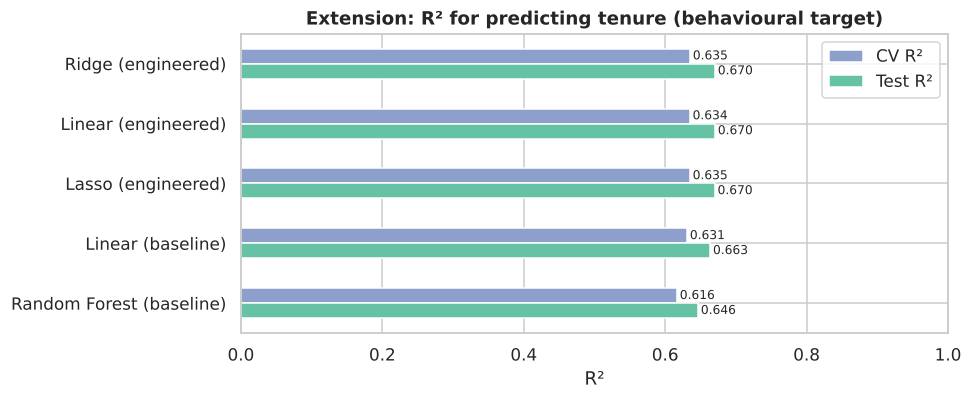

In [27]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ten_df[["CV R²", "Test R²"]].plot.barh(ax=ax, color=["#8da0cb", "#66c2a5"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
ax.set(title="Extension: R² for predicting tenure (behavioural target)", xlabel="R²", xlim=(0, 1))
ax.invert_yaxis()
plt.tight_layout(); plt.savefig("figures/tenure_extension_r2.png", bbox_inches="tight"); plt.show()

With a behavioural target, test R² drops to about 0.65–0.67: about a third of the variation in how long customers stay is not
explained by the available attributes (for example service quality, competitor offers, life events). Feature engineering still helps a little (test RMSE 14.56 → 14.41 months), regularisation
makes almost no difference, and the linear models beat the Random Forest. Contract length,
add-on count and payment method are the main drivers, which matches the churn findings in Deliverable 1.

## 10. Summary of Results and Insights

The results printed below are generated from the tables above.

In [28]:
best = summary.index[0]
print("=" * 78)
print("TotalCharges models, ranked by test RMSE")
print("=" * 78)
print(summary[["CV R² (mean)", "CV RMSE", "Test R²", "Test RMSE", "Test MAE"]].round(4).to_string())
print(f"\nBest model: {best}  (test R² = {summary.loc[best, 'Test R²']:.4f}, "
      f"test RMSE = ${summary.loc[best, 'Test RMSE']:,.2f})")
print(f"Ridge alpha = {ridge_alpha:.4g}, Lasso alpha = {lasso_alpha:.4g}; Lasso removed {n_zero} of {len(coef)} features.")

TotalCharges models, ranked by test RMSE
                          CV R² (mean)   CV RMSE  Test R²  Test RMSE  Test MAE
Lasso (engineered)              0.9987   81.6591   0.9986    85.0037   54.2019
Linear (engineered)             0.9987   81.8499   0.9986    85.3166   54.5319
Ridge (engineered)              0.9987   81.8495   0.9986    85.3196   54.5445
Random Forest (baseline)        0.9956  149.4878   0.9953   155.7184   94.6677
Linear (baseline)               0.9068  689.8596   0.9043   705.4355  571.2020

Best model: Lasso (engineered)  (test R² = 0.9986, test RMSE = $85.00)
Ridge alpha = 0.3728, Lasso alpha = 0.8685; Lasso removed 34 of 51 features.


### Which model performed best?
- **Feature engineering made by far the biggest difference.** Moving from raw to engineered features with the *same* algorithm
  (ordinary least squares) cut test RMSE by about **88%** and raised R² from about 0.91 to about 0.999. The tenure × service interactions
  turned a multiplicative relationship (months × price) into one a linear model can represent.
- **Lasso (engineered) achieved the best scores** (test R² = 0.9986, test RMSE ≈ \$85, MAE ≈ \$54), essentially tied with Ridge and
  plain OLS on the engineered features (test RMSE within \$0.35 of each other), so the difference is not practically meaningful.
  Lasso is the **recommended model** because it matches the best accuracy with a much **simpler** model: it set **34 of 51**
  coefficients to exactly zero, and just **7 tenure-based pricing features** carry almost all the weight. Ridge's chosen α (≈0.37) and
  Lasso's (≈0.87) are small, because once the right features exist there is little noise to regularise away.
- **Random Forest** (on raw features) did better than the baseline linear model because it learns interactions on its own, but it
  was still clearly behind the engineered linear models and much harder to interpret. Domain-driven features beat model complexity here.
- **Generalisation:** CV and test results agree closely for every model (small RMSE gaps), CV fold scores have low spread, and the
  learning and validation curves show no overfitting. The models should generalise reliably to new customers.

### Key insights
1. Customer revenue is almost exactly **tenure × (sum of service prices)**. Once the features reflect that, a simple linear model is nearly perfect.
2. The model **recovers the company's price list** from revenue data alone (for example, fiber optic is the most expensive component and each streaming service adds about \$10/month).
3. **Lasso confirmed the value of the engineered features.** Because MultipleLines, OnlineBackup, DeviceProtection and TechSupport each cost about \$5/month, Lasso dropped their separate tenure interactions and represented them through the single engineered feature `tenure_x_num_services`, which ended up as the largest coefficient in the model.
4. **Demographics add essentially nothing** to revenue once services are known. Lasso removed every demographic dummy and left the tenure × demographic interactions with negligible weights, consistent with Deliverable 1.
5. Remaining errors (MAE of a few tens of dollars) come from **price changes during a customer's lifetime**, the same deviations seen in Deliverable 1's consistency check.
6. Behavioural targets such as **tenure** are much harder to predict (test R² ≈ 0.66–0.67), which motivates the classification and clustering work in Deliverable 3.

---
# Part 3 – Classification, Clustering and Association Rules (Deliverable 3)

In [29]:
# --- Data already loaded and cleaned in Part 1 --------------------------------
print("Shape:", df.shape, "| missing values:", int(df.isnull().sum().sum()))

# Engineered features reused from Deliverable 2
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_addons"] = (df[addon_cols] == "Yes").sum(axis=1)
df["auto_payment"] = df["PaymentMethod"].str.contains("auto").astype(int)
df["has_family"] = ((df["Partner"] == "Yes") | (df["Dependents"] == "Yes")).astype(int)
df["contract_months"] = df["Contract"].map({"Month-to-month": 1, "One year": 12, "Two year": 24})
df.head(3)

Shape: (7043, 21) | missing values: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_flag,num_addons,auto_payment,has_family,contract_months
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,1,0,1,1
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,2,0,0,12
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,2,0,0,1


---
# Part A – Classification: Predicting Customer Churn

**Goal:** predict whether a customer will churn (`Churn` = Yes/No) from their demographics, account and service information.
A good model lets the company target retention offers *before* customers leave.

**Things to keep in mind from Deliverable 1:**
- **Class imbalance:** only 26.5% of customers churn. A model that always predicts "No" would be 73.5% accurate and useless,
  so **F1-score (for the churn class) and ROC-AUC** are the main metrics, and splits are **stratified**.
- **Different feature scales** (tenure 0–72, TotalCharges 0–8,685): k-NN and SVM rely on distances, so features are **standardised**
  inside pipelines (the scaler is fit only on training data).

## 1. Data Preparation

In [30]:
# One-hot encode the categorical predictors (drop_first avoids redundant dummy columns)
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
            "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaperlessBilling", "PaymentMethod"]
X = pd.get_dummies(df.drop(columns=["Churn", "Churn_flag"]), columns=cat_cols, drop_first=True, dtype=float)
y = df["Churn_flag"].values      # 1 = churned, 0 = stayed

# Stratified 80/20 split keeps the 26.5% churn rate in both sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Features: {X.shape[1]}")
print(f"Train: {X_train.shape[0]:,} rows (churn rate {y_train.mean():.1%})")
print(f"Test : {X_test.shape[0]:,} rows (churn rate {y_test.mean():.1%})")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Features: 27
Train: 5,634 rows (churn rate 26.5%)
Test : 1,409 rows (churn rate 26.5%)


## 2. Baseline Classification Models

| Model | How it works | Settings and why |
|---|---|---|
| **Decision Tree (default)** | Splits the data with if/then rules | Default settings (fully grown tree) to show the starting point *before* tuning |
| **k-Nearest Neighbours** | Predicts by majority vote of the *k* most similar customers | Standardised features; *k* chosen with a validation curve (below) |
| **Gaussian Naïve Bayes** | Probabilistic model assuming features are independent given the class | No hyperparameters to tune; fast baseline |
| **Support Vector Machine** | Finds the maximum-margin boundary, with an RBF kernel for non-linear patterns | Standardised features, `class_weight="balanced"` to counter the imbalance |
| **Logistic Regression** (reference) | Linear probabilistic classifier | Standard benchmark for churn problems, `class_weight="balanced"` |

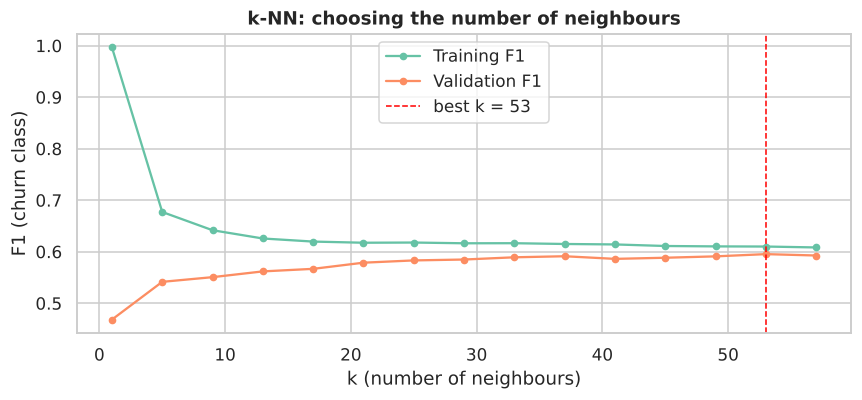

Selected k = 53. A small k overfits (training F1 near 1.0); a larger k smooths the decision boundary.


In [31]:
# --- Choose k for k-NN with a validation curve (5-fold stratified CV on the training data) ---
k_range = list(range(1, 61, 4))
knn_pipe = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier())])
tr_f1, va_f1 = validation_curve(knn_pipe, X_train, y_train, param_name="model__n_neighbors",
                                param_range=k_range, cv=cv, scoring="f1", n_jobs=-1)
best_k = k_range[int(np.argmax(va_f1.mean(1)))]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(k_range, tr_f1.mean(1), "o-", ms=4, label="Training F1")
ax.plot(k_range, va_f1.mean(1), "o-", ms=4, label="Validation F1")
ax.axvline(best_k, color="red", ls="--", lw=1, label=f"best k = {best_k}")
ax.set(title="k-NN: choosing the number of neighbours", xlabel="k (number of neighbours)", ylabel="F1 (churn class)")
ax.legend()
plt.tight_layout(); plt.savefig("figures/knn_k_selection.png", bbox_inches="tight"); plt.show()
print(f"Selected k = {best_k}. A small k overfits (training F1 near 1.0); a larger k smooths the decision boundary.")

In [32]:
models = {
    "Decision Tree (default)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "k-NN": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=best_k))]),
    "Naive Bayes": Pipeline([("scaler", StandardScaler()), ("model", GaussianNB())]),
    "SVM (RBF)": Pipeline([("scaler", StandardScaler()),
                           ("model", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE))]),
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=5000, class_weight="balanced"))]),
}

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows[name] = {f"CV {m}": res[f"test_{m}"].mean() for m in scoring}
    print(f"{name:<25} CV F1 = {res['test_f1'].mean():.3f}   CV ROC-AUC = {res['test_roc_auc'].mean():.3f}")
pd.DataFrame(cv_rows).T.round(3)

Decision Tree (default)   CV F1 = 0.482   CV ROC-AUC = 0.649


k-NN                      CV F1 = 0.595   CV ROC-AUC = 0.831
Naive Bayes               CV F1 = 0.617   CV ROC-AUC = 0.831


SVM (RBF)                 CV F1 = 0.621   CV ROC-AUC = 0.827
Logistic Regression       CV F1 = 0.629   CV ROC-AUC = 0.846


,CV accuracy,CV precision,CV recall,CV f1,CV roc_auc
Decision Tree (default),0.725,0.481,0.484,0.482,0.649
k-NN,0.794,0.622,0.572,0.595,0.831
Naive Bayes,0.739,0.505,0.794,0.617,0.831
SVM (RBF),0.749,0.518,0.775,0.621,0.827
Logistic Regression,0.750,0.518,0.801,0.629,0.846


The **untuned Decision Tree performs worst** (lowest F1 and ROC-AUC). A fully grown tree memorises the training data and
overfits. This makes it the natural choice for hyperparameter tuning.

## 3. Hyperparameter Tuning: Decision Tree with GridSearchCV

**Technique:** an exhaustive **grid search with 5-fold stratified cross-validation** (`GridSearchCV`). Every combination of
the hyperparameters below is trained and validated on 5 different folds of the training data. The combination with the
highest **mean F1-score** (churn class) is selected and refit on the whole training set. The test set is not touched during tuning.

| Hyperparameter | Values searched | What it controls |
|---|---|---|
| `criterion` | gini, entropy | How split quality is measured |
| `max_depth` | 3, 4, 5, 6, 7, 8, 10, 12, None | Maximum tree depth: the main control on complexity and overfitting |
| `min_samples_leaf` | 1, 5, 10, 20, 40, 80 | Minimum customers per leaf: stops rules based on very few customers |
| `class_weight` | None, balanced | `balanced` gives churners more weight to counter the 73/27 imbalance |
| `ccp_alpha` | 0, 0.0005, 0.001, 0.003 | Cost-complexity pruning: removes branches that add little |

F1 was chosen as the selection metric because it balances **precision** (not wasting retention offers on loyal customers)
and **recall** (not missing customers who are about to leave).

In [33]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6, 7, 8, 10, 12, None],
    "min_samples_leaf": [1, 5, 10, 20, 40, 80],
    "class_weight": [None, "balanced"],
    "ccp_alpha": [0.0, 0.0005, 0.001, 0.003],
}
n_combos = int(np.prod([len(v) for v in param_grid.values()]))
print(f"Grid size: {n_combos} combinations x 5 folds = {n_combos * 5:,} model fits")

grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                    scoring={"f1": "f1", "roc_auc": "roc_auc", "accuracy": "accuracy"},
                    refit="f1", cv=cv, n_jobs=-1, return_train_score=True)
t0 = time.time()
grid.fit(X_train, y_train)
print(f"Search finished in {time.time() - t0:.1f} s")
print("\nBest hyperparameters:", grid.best_params_)
print(f"Best mean CV F1: {grid.best_score_:.3f}")
bi = grid.best_index_
print(f"Mean CV ROC-AUC of the best model: {grid.cv_results_['mean_test_roc_auc'][bi]:.3f}")
print(f"Mean train F1 vs CV F1: {grid.cv_results_['mean_train_f1'][bi]:.3f} vs {grid.best_score_:.3f} "
      "(small gap = little overfitting)")

Grid size: 864 combinations x 5 folds = 4,320 model fits


Search finished in 132.2 s

Best hyperparameters: {'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}
Best mean CV F1: 0.619
Mean CV ROC-AUC of the best model: 0.816
Mean train F1 vs CV F1: 0.622 vs 0.619 (small gap = little overfitting)


In [34]:
# --- Top 10 parameter combinations -------------------------------------------
res = pd.DataFrame(grid.cv_results_)
top10 = (res.sort_values("rank_test_f1")
         [["param_criterion", "param_max_depth", "param_min_samples_leaf", "param_class_weight", "param_ccp_alpha",
           "mean_test_f1", "std_test_f1", "mean_test_roc_auc", "mean_train_f1"]].head(10))
top10.columns = ["criterion", "max_depth", "min_samples_leaf", "class_weight", "ccp_alpha",
                 "CV F1", "CV F1 std", "CV ROC-AUC", "Train F1"]
top10.round(4)

,criterion,max_depth,min_samples_leaf,class_weight,ccp_alpha,CV F1,CV F1 std,CV ROC-AUC,Train F1
541,gini,3,5,balanced,0.001,0.6194,0.0182,0.8161,0.6223
542,gini,3,10,balanced,0.001,0.6194,0.0182,0.8161,0.6223
545,gini,3,80,balanced,0.001,0.6194,0.0182,0.8161,0.6223
544,gini,3,40,balanced,0.001,0.6194,0.0182,0.8161,0.6223
543,gini,3,20,balanced,0.001,0.6194,0.0182,0.8161,0.6223
540,gini,3,1,balanced,0.001,0.6194,0.0182,0.8161,0.6223
596,entropy,3,10,balanced,0.001,0.6194,0.0182,0.8169,0.6223
597,entropy,3,20,balanced,0.001,0.6194,0.0182,0.8169,0.6223
595,entropy,3,5,balanced,0.001,0.6194,0.0182,0.8169,0.6223
594,entropy,3,1,balanced,0.001,0.6194,0.0182,0.8169,0.6223


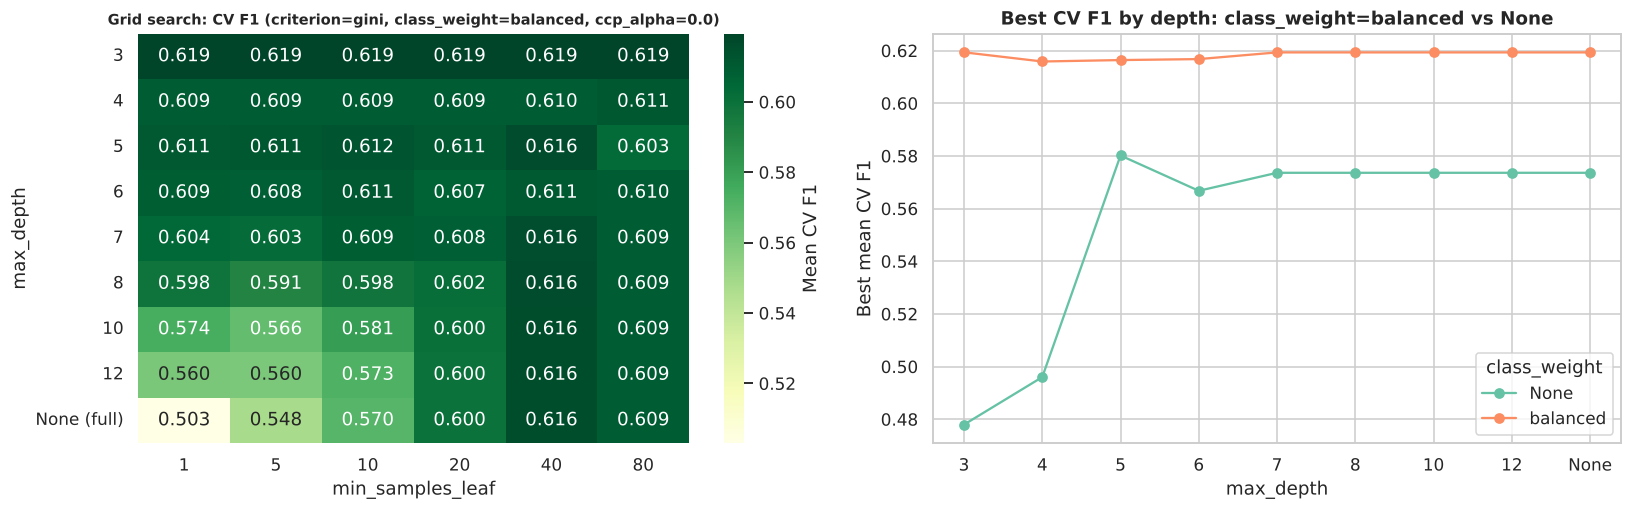

In [35]:
# --- Visualise the search: CV F1 over max_depth x min_samples_leaf ----------------
# (other hyperparameters fixed at their best values)
bp = grid.best_params_
to_str = lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(int(v)) if isinstance(v, (int, float, np.integer, np.floating)) else str(v)
res["depth_s"] = res["param_max_depth"].apply(to_str)
res["cw_s"] = res["param_class_weight"].apply(lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
sub = res[(res.param_criterion == bp["criterion"]) & (res.cw_s == str(bp["class_weight"])) &
          (res.param_ccp_alpha == bp["ccp_alpha"])].copy()
sub["max_depth"] = sub["depth_s"].replace("None", "None (full)")
heat = sub.pivot_table(index="max_depth", columns="param_min_samples_leaf", values="mean_test_f1")
heat = heat.reindex([str(d) for d in [3, 4, 5, 6, 7, 8, 10, 12]] + ["None (full)"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGn", ax=axes[0], cbar_kws={"label": "Mean CV F1"})
axes[0].set(title=f"Grid search: CV F1 (criterion={bp['criterion']}, class_weight={bp['class_weight']}, "
                  f"ccp_alpha={bp['ccp_alpha']})", xlabel="min_samples_leaf", ylabel="max_depth")
axes[0].title.set_fontsize(9.5)

# Effect of class_weight and depth (best of the other params per cell)
eff = res.groupby(["depth_s", "cw_s"])["mean_test_f1"].max().unstack()
eff = eff.reindex([str(d) for d in [3, 4, 5, 6, 7, 8, 10, 12]] + ["None"])
eff.plot(marker="o", ax=axes[1])
axes[1].set(title="Best CV F1 by depth: class_weight=balanced vs None", xlabel="max_depth", ylabel="Best mean CV F1")
axes[1].legend(title="class_weight")
plt.tight_layout(); plt.savefig("figures/dt_grid_search.png", bbox_inches="tight"); plt.show()

**Interpreting the chosen parameters** (`max_depth=3`, `class_weight="balanced"`, `criterion="gini"`):
- **A shallow tree (depth 3, only 8 leaves) gives the best F1.** The default tree grew to depth 25 with more than 1,000 leaves and overfit badly.
- **Deep trees only recover when leaves are forced to be large.** In the heatmap, deep trees with `min_samples_leaf` = 1–10 score worst
  (as low as 0.50 for an unlimited tree), but with `min_samples_leaf = 40` they reach ≈0.616. Both depth limits and leaf-size limits do the same job: they stop
  the tree from learning rules from a handful of customers.
- **`min_samples_leaf` and `ccp_alpha` make no difference at depth 3.** A depth-3 tree's leaves already hold hundreds of customers and it
  has no weak branches to prune, so many combinations tie on CV F1. Among tied combinations, `GridSearchCV` keeps the first one in the grid.
- **`class_weight="balanced"` is the single most important setting.** It lifts F1 at every depth (right-hand plot) because, without it, the
  tree favours the majority "stay" class and misses many churners.
- Training F1 (0.622) and CV F1 (0.619) are almost identical, so **the tuned model does not overfit**, and a three-level tree is
  simple enough to explain to a business audience.

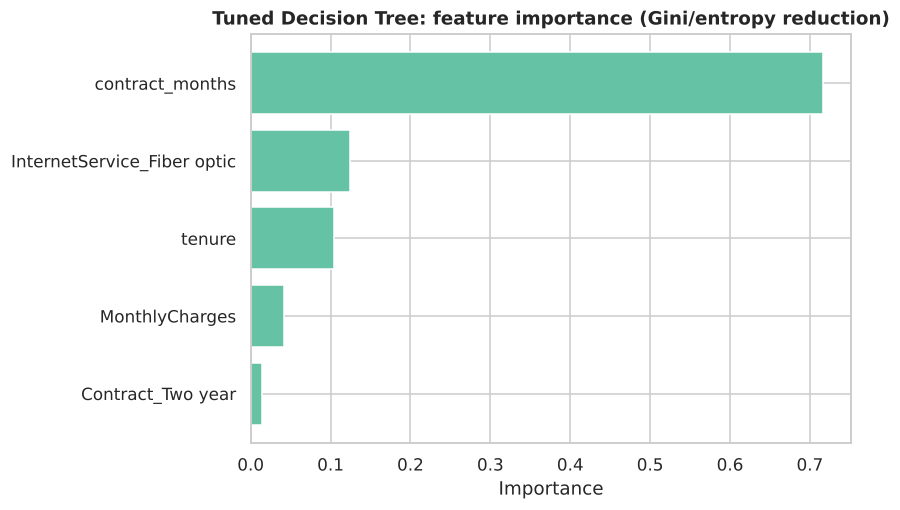

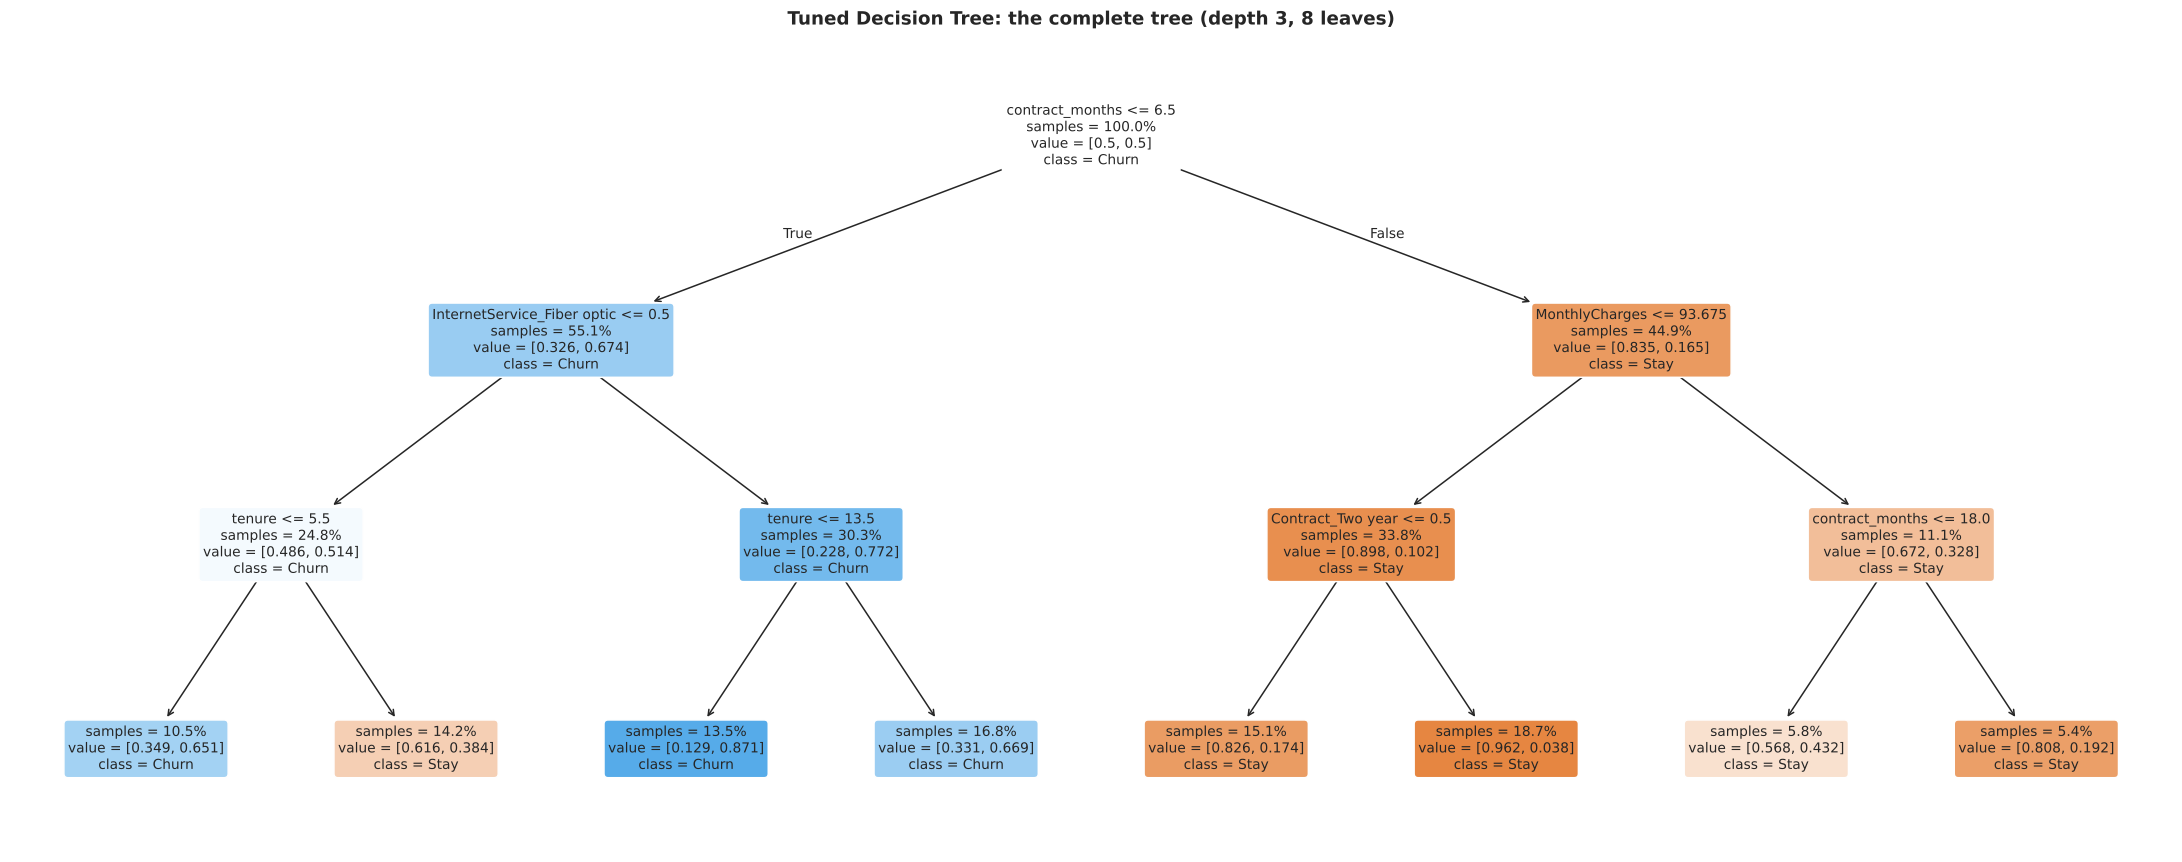

In [36]:
# --- Tuned tree: feature importances and top of the tree --------------------------
best_tree = grid.best_estimator_
imp = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=False)
imp = imp[imp > 0].head(12)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(imp.index[::-1], imp.values[::-1], color="#66c2a5")
ax.set(title="Tuned Decision Tree: feature importance (Gini/entropy reduction)", xlabel="Importance")
plt.tight_layout(); plt.savefig("figures/dt_feature_importance.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(best_tree, feature_names=X.columns, class_names=["Stay", "Churn"], filled=True,
          rounded=True, impurity=False, proportion=True, fontsize=9, ax=ax)
ax.set_title("Tuned Decision Tree: the complete tree (depth 3, 8 leaves)")
plt.tight_layout(); plt.savefig("figures/dt_tree_top_levels.png", bbox_inches="tight"); plt.show()

## 4. Evaluation on the Held-out Test Set

In [37]:
# Add the tuned tree to the model set, fit everything on the full training data and evaluate on the test set
models["Decision Tree (tuned)"] = best_tree
order = ["Decision Tree (default)", "Decision Tree (tuned)", "k-NN", "Naive Bayes", "SVM (RBF)", "Logistic Regression"]

test_rows, probas, preds = {}, {}, {}
for name in order:
    m = models[name]
    if name != "Decision Tree (tuned)":          # the tuned tree is already refit on the full training set
        m.fit(X_train, y_train)
    p = m.predict(X_test)
    pr = m.predict_proba(X_test)[:, 1]
    preds[name], probas[name] = p, pr
    test_rows[name] = {"Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                       "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, pr)}

cv_rows["Decision Tree (tuned)"] = {"CV f1": grid.best_score_,
                                    "CV roc_auc": grid.cv_results_["mean_test_roc_auc"][bi]}
results = pd.DataFrame(test_rows).T.loc[order]
results.insert(0, "CV F1", [cv_rows[n]["CV f1"] for n in order])
results.to_csv("classification_results.csv")
results.style.format("{:.3f}").highlight_max(subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"], color="#c7e9c0")

,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree (default),0.482,0.730,0.492,0.505,0.499,0.658
Decision Tree (tuned),0.619,0.746,0.514,0.783,0.621,0.816
k-NN,0.595,0.776,0.580,0.570,0.575,0.819
Naive Bayes,0.617,0.732,0.497,0.778,0.606,0.821
SVM (RBF),0.621,0.742,0.509,0.757,0.609,0.818
Logistic Regression,0.629,0.739,0.505,0.781,0.613,0.841


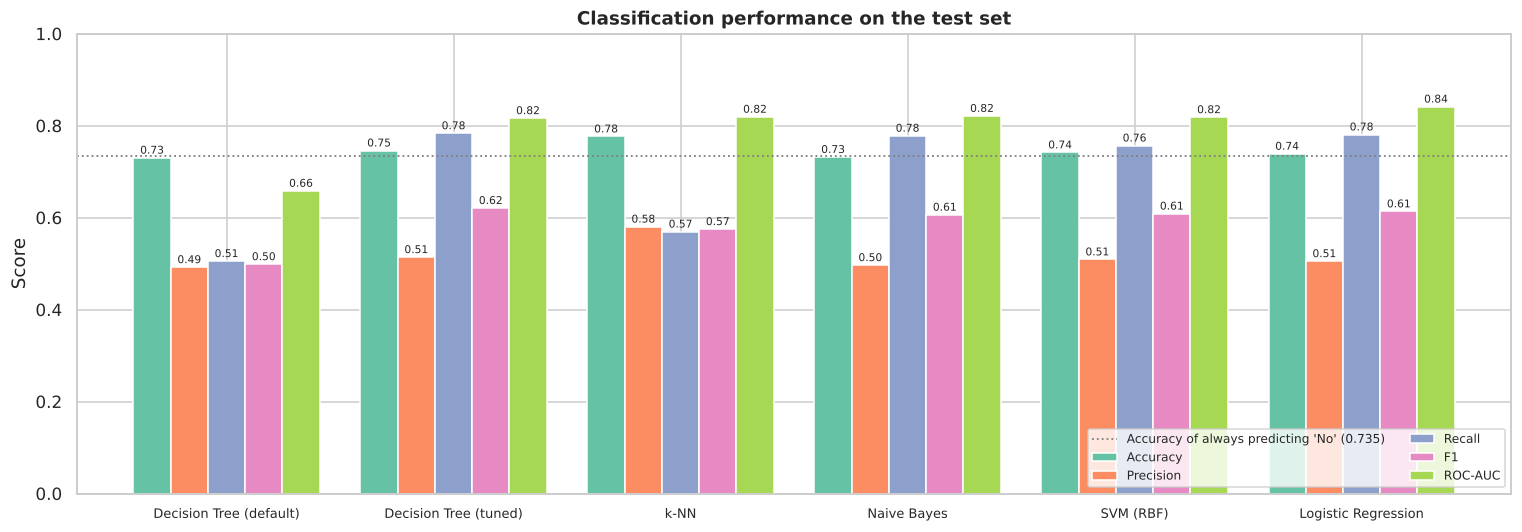

In [38]:
# --- 4.1 Metric comparison bar chart -----------------------------------------------
fig, ax = plt.subplots(figsize=(14, 5))
results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot.bar(ax=ax, width=0.82,
                                                                       color=sns.color_palette("Set2", 5))
ax.axhline(1 - y_test.mean(), color="grey", ls=":", lw=1.2, label=f"Accuracy of always predicting 'No' ({1 - y_test.mean():.3f})")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7, padding=1)
ax.set(title="Classification performance on the test set", ylabel="Score", ylim=(0, 1.0), xlabel="")
ax.tick_params(axis="x", rotation=0, labelsize=8.5)
ax.legend(loc="lower right", fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig("figures/classification_metrics_comparison.png", bbox_inches="tight"); plt.show()

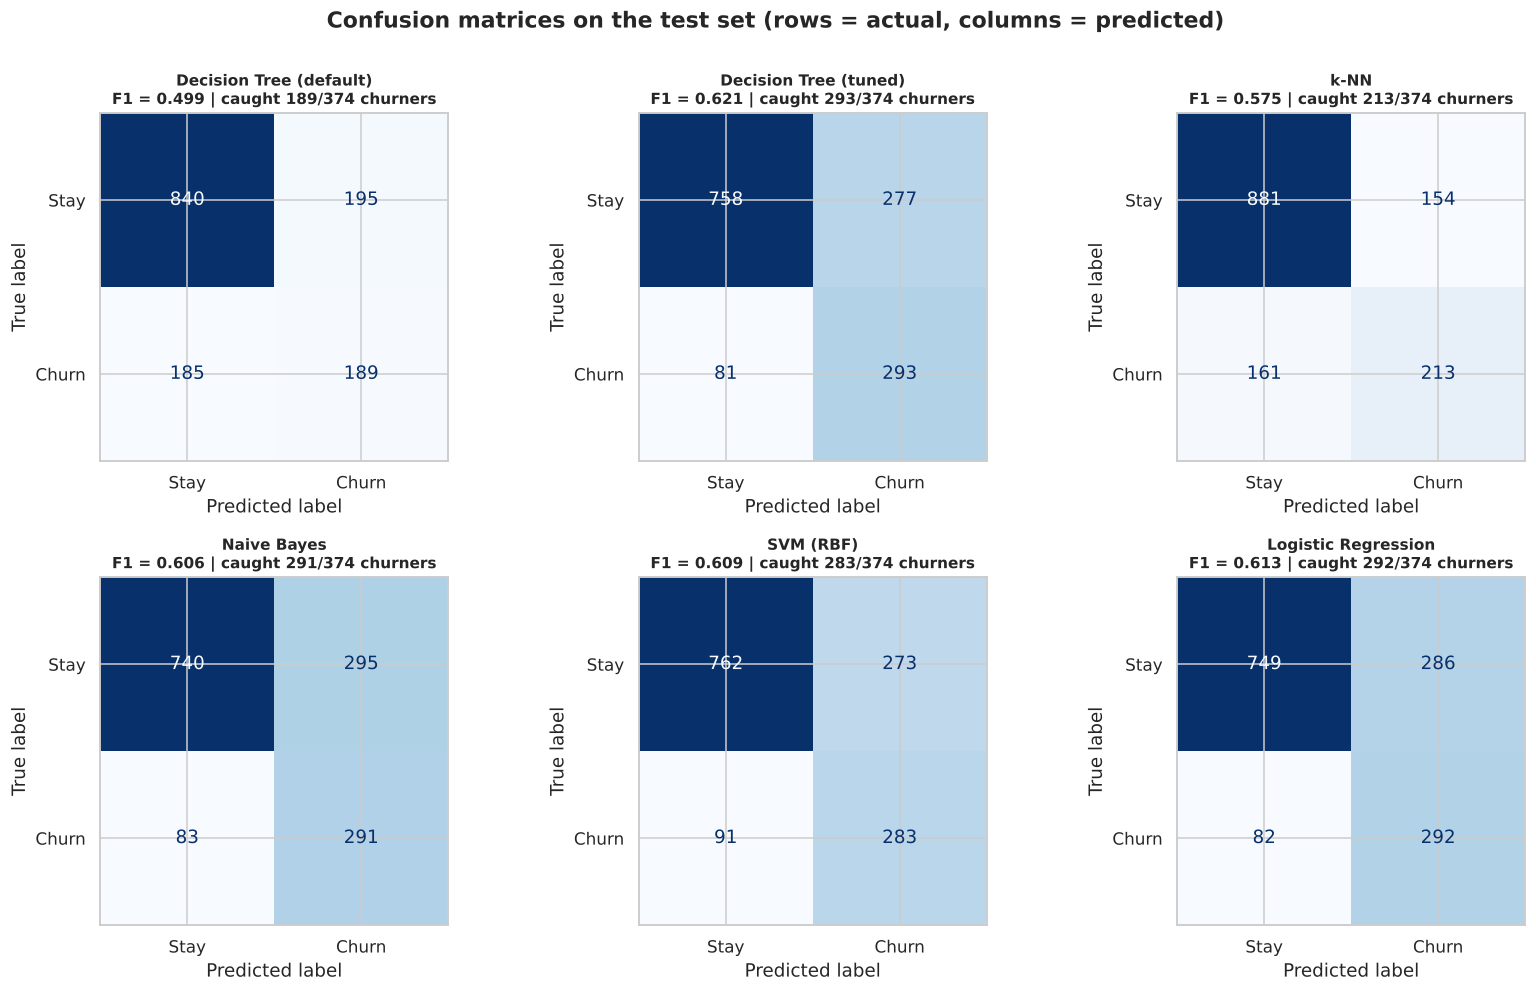

In [39]:
# --- 4.2 Confusion matrices -----------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.flat, order):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\nF1 = {results.loc[name, 'F1']:.3f} | caught {tp}/{tp + fn} churners", fontsize=10)
fig.suptitle("Confusion matrices on the test set (rows = actual, columns = predicted)", weight="bold", y=1.0)
plt.tight_layout(); plt.savefig("figures/confusion_matrices.png", bbox_inches="tight"); plt.show()

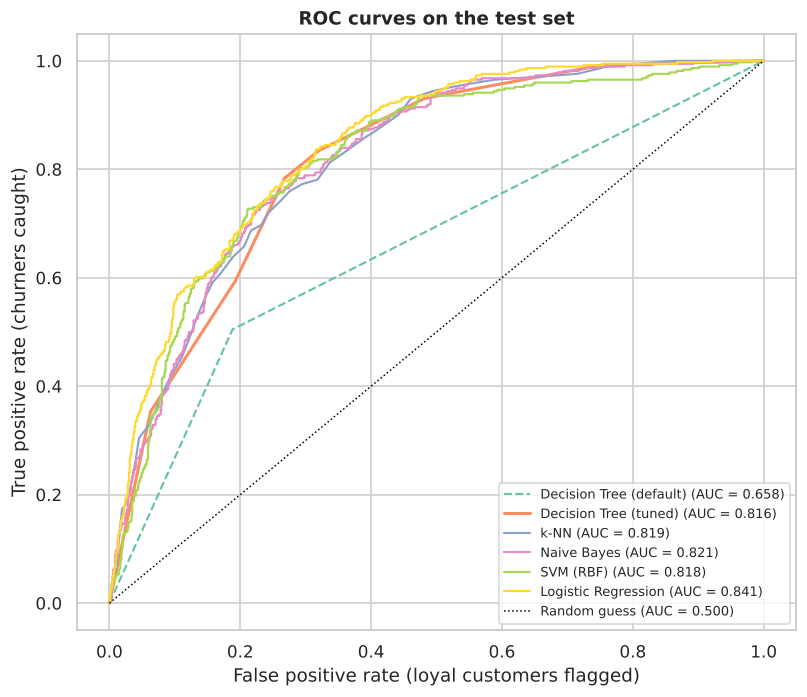

In [40]:
# --- 4.3 ROC curves -------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for name in order:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    ax.plot(fpr, tpr, lw=2 if "tuned" in name else 1.4, ls="--" if "default" in name else "-",
            label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=1, label="Random guess (AUC = 0.500)")
ax.set(title="ROC curves on the test set", xlabel="False positive rate (loyal customers flagged)",
       ylabel="True positive rate (churners caught)")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.savefig("figures/roc_curves.png", bbox_inches="tight"); plt.show()

In [41]:
# --- 4.4 Before vs after tuning ------------------------------------------------------
cmp = results.loc[["Decision Tree (default)", "Decision Tree (tuned)"], ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
cmp.loc["Improvement"] = cmp.iloc[1] - cmp.iloc[0]
print("Decision tree before vs after hyperparameter tuning (test set):")
display(cmp.round(3))
print(f"Tuned tree depth = {best_tree.get_depth()}, leaves = {best_tree.get_n_leaves()} "
      f"(default tree: depth = {models['Decision Tree (default)'].get_depth()}, "
      f"leaves = {models['Decision Tree (default)'].get_n_leaves()})")

Decision tree before vs after hyperparameter tuning (test set):


,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree (default),0.730,0.492,0.505,0.499,0.658
Decision Tree (tuned),0.746,0.514,0.783,0.621,0.816
Improvement,0.016,0.022,0.278,0.122,0.158


Tuned tree depth = 3, leaves = 8 (default tree: depth = 25, leaves = 1101)


In [42]:
# Detailed per-class report for the tuned decision tree
print(classification_report(y_test, preds["Decision Tree (tuned)"], target_names=["Stay", "Churn"], digits=3))

              precision    recall  f1-score   support

        Stay      0.903     0.732     0.809      1035
       Churn      0.514     0.783     0.621       374

    accuracy                          0.746      1409
   macro avg      0.709     0.758     0.715      1409
weighted avg      0.800     0.746     0.759      1409



**Classification takeaways**
- **Accuracy is misleading here.** k-NN has the *highest* accuracy (0.776) but catches only 57% of churners and has the lowest F1 of the
  tuned or well-configured models. F1, recall and ROC-AUC tell the real story.
- **Tuning transformed the Decision Tree**: from the worst model to one competitive with SVM and Logistic Regression, while staying
  small and readable. The tuned tree's top splits (contract type, tenure, internet service) are rules a retention team can use directly.
- **The tuned Decision Tree has the best F1 (0.621)** and Logistic Regression the best ROC-AUC (0.841). The models with balanced class
  weights (tuned tree, SVM, Logistic Regression) and Naïve Bayes catch about 76–78% of churners, at the cost of more false alarms. For retention that trade-off is usually worth it: a discount offered to a loyal customer costs far less than losing a customer.

---
# Part B – Clustering: Customer Segmentation

**Goal:** group customers into segments with similar *relationship and spending profiles* without using the churn label,
then check how churn differs between the segments that were discovered.

**Features used** (standardised, so each contributes equally to the distance):
- `tenure`: length of relationship
- `MonthlyCharges`: price level
- `num_addons`: depth of the service bundle (0–6)
- `contract_months`: commitment level (1, 12, 24)

`TotalCharges` was left out because it is largely tenure × MonthlyCharges (Deliverable 2) and would double-count those two dimensions.

## 5. K-Means Clustering

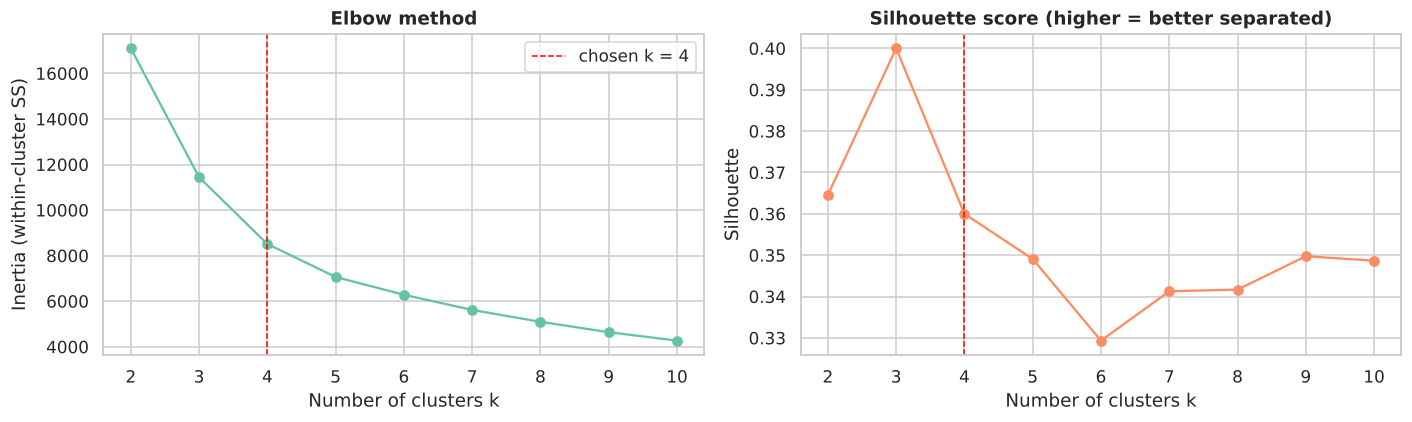

k,2,3,4,5,6,7,8,9,10
inertia,17101.000,11443.0,8510.00,7063.000,6283.000,5615.000,5094.000,4639.00,4269.000
silhouette,0.365,0.4,0.36,0.349,0.329,0.341,0.342,0.35,0.349
inertia drop vs k-1,NaN,5658.0,2933.00,1448.000,779.000,668.000,521.000,455.00,370.000


In [43]:
clu_features = ["tenure", "MonthlyCharges", "num_addons", "contract_months"]
scaler_c = StandardScaler()
Z = scaler_c.fit_transform(df[clu_features])

# --- Choose k: elbow method (inertia) and silhouette score ------------------------
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(list(ks), inertia, "o-"); ax[0].axvline(4, color="red", ls="--", lw=1, label="chosen k = 4")
ax[0].set(title="Elbow method", xlabel="Number of clusters k", ylabel="Inertia (within-cluster SS)"); ax[0].legend()
ax[1].plot(list(ks), sil, "o-", color="#fc8d62"); ax[1].axvline(4, color="red", ls="--", lw=1)
ax[1].set(title="Silhouette score (higher = better separated)", xlabel="Number of clusters k", ylabel="Silhouette")
plt.tight_layout(); plt.savefig("figures/kmeans_k_selection.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 0), "silhouette": np.round(sil, 3),
              "inertia drop vs k-1": np.r_[np.nan, -np.diff(inertia)].round(0)}).set_index("k").T

**Choosing k = 4.** The silhouette score peaks at k = 3, with k = 4 close behind, and the elbow curve flattens after k = 4 (the reduction in
inertia roughly halves from k = 4 to k = 5). We choose **k = 4** because it keeps good separation while splitting the very large
high-churn group found at k = 3 into **two segments that need different retention strategies** (new low-spend customers vs
established high-spend customers without contracts). In segmentation, being able to act on the clusters is as important as the
statistical score.

In [44]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Z)
df["cluster_id"] = kmeans.labels_
print(f"Silhouette score for k = {K}: {silhouette_score(Z, kmeans.labels_):.3f}")

# --- Profile each cluster (churn is NOT used for clustering, only for interpretation) ---
profile = df.groupby("cluster_id").agg(
    customers=("tenure", "size"), tenure=("tenure", "mean"), monthly_charges=("MonthlyCharges", "mean"),
    num_addons=("num_addons", "mean"), contract_months=("contract_months", "mean"),
    pct_fiber=("InternetService", lambda s: (s == "Fiber optic").mean() * 100),
    pct_no_internet=("InternetService", lambda s: (s == "No").mean() * 100),
    pct_month_to_month=("Contract", lambda s: (s == "Month-to-month").mean() * 100),
    pct_electronic_check=("PaymentMethod", lambda s: (s == "Electronic check").mean() * 100),
    churn_rate=("Churn_flag", lambda s: s.mean() * 100))

# --- Give each cluster a descriptive name based on its profile ----------------------
names = {}
remaining = set(profile.index)
c = profile.loc[list(remaining), "pct_no_internet"].idxmax(); names[c] = "Basic Phone-Only Loyalists"; remaining.remove(c)
c = profile.loc[list(remaining), "tenure"].idxmin();          names[c] = "New Low-Commitment Customers"; remaining.remove(c)
c = profile.loc[list(remaining), "contract_months"].idxmax(); names[c] = "Established Premium Bundlers"; remaining.remove(c)
c = remaining.pop();                                          names[c] = "High-Spend Flexible (At Risk)"
df["segment"] = df["cluster_id"].map(names)
profile.index = profile.index.map(names)
profile = profile.sort_values("churn_rate", ascending=False)
profile["share_%"] = profile["customers"] / len(df) * 100
profile.to_csv("cluster_profiles.csv")
profile.round(1)

Silhouette score for k = 4: 0.360


,customers,tenure,monthly_charges,num_addons,contract_months,pct_fiber,pct_no_internet,pct_month_to_month,pct_electronic_check,churn_rate,share_%
cluster_id,,,,,,,,,,,
High-Spend Flexible (At Risk),2151,28.4,84.6,2.7,2.7,73.8,0.0,84.2,51.2,39.3,30.5
New Low-Commitment Customers,2228,9.2,46.9,0.6,1.9,29.6,28.6,92.1,38.6,38.9,31.6
Established Premium Bundlers,1629,60.6,88.3,4.3,19.2,51.7,0.0,0.6,21.2,8.7,23.1
Basic Phone-Only Loyalists,1035,46.1,24.9,0.3,20.2,0.6,85.8,0.2,5.6,1.5,14.7


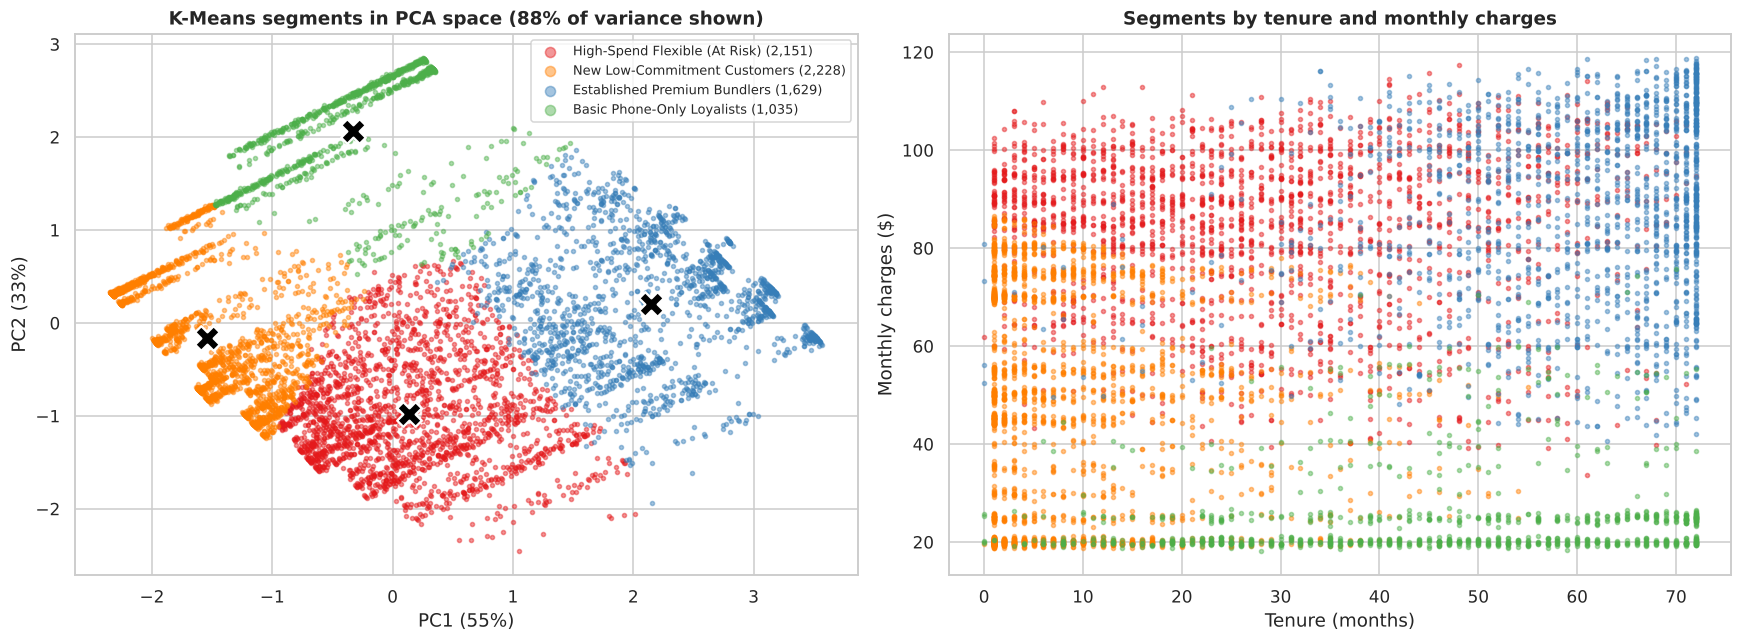

In [45]:
# --- 5.1 Visualise clusters in 2-D with PCA -----------------------------------------
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(Z)
centers = pca.transform(kmeans.cluster_centers_)
seg_order = profile.index.tolist()
palette = dict(zip(seg_order, ["#e41a1c", "#ff7f00", "#377eb8", "#4daf4a"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for seg in seg_order:
    m = df["segment"] == seg
    axes[0].scatter(P[m, 0], P[m, 1], s=7, alpha=.45, color=palette[seg], label=f"{seg} ({m.sum():,})")
for cid, (cx, cy) in enumerate(centers):
    axes[0].scatter(cx, cy, s=260, marker="X", color="black", edgecolor="white", lw=1.5)
axes[0].set(title=f"K-Means segments in PCA space ({pca.explained_variance_ratio_.sum():.0%} of variance shown)",
            xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axes[0].legend(fontsize=8.5, markerscale=2.5, loc="best")

# Same clusters in the original, interpretable feature space
for seg in seg_order:
    m = df["segment"] == seg
    axes[1].scatter(df.loc[m, "tenure"], df.loc[m, "MonthlyCharges"], s=7, alpha=.45, color=palette[seg], label=seg)
axes[1].set(title="Segments by tenure and monthly charges", xlabel="Tenure (months)", ylabel="Monthly charges ($)")
plt.tight_layout(); plt.savefig("figures/kmeans_clusters_scatter.png", bbox_inches="tight"); plt.show()

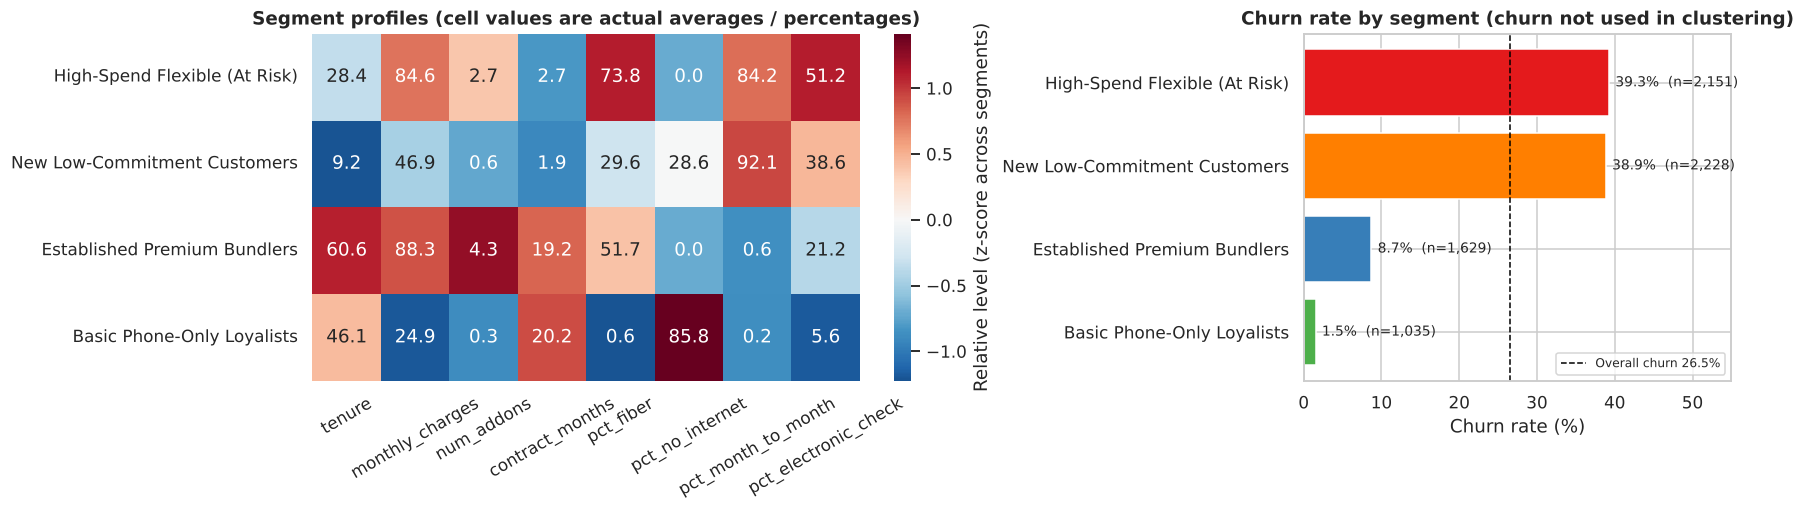

In [46]:
# --- 5.2 Cluster profile heatmap and churn rate per segment ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
prof_cols = ["tenure", "monthly_charges", "num_addons", "contract_months", "pct_fiber", "pct_no_internet",
             "pct_month_to_month", "pct_electronic_check"]
# Colour by standardised value (relative to the other segments), annotate with actual values
rel = (profile[prof_cols] - profile[prof_cols].mean()) / profile[prof_cols].std()
sns.heatmap(rel, annot=profile[prof_cols].round(1), fmt="", cmap="RdBu_r", center=0, ax=axes[0],
            cbar_kws={"label": "Relative level (z-score across segments)"})
axes[0].set(title="Segment profiles (cell values are actual averages / percentages)", ylabel="")
axes[0].tick_params(axis="x", rotation=30)

bars = axes[1].barh(profile.index, profile["churn_rate"], color=[palette[s] for s in profile.index])
axes[1].axvline(df["Churn_flag"].mean() * 100, color="black", ls="--", lw=1, label="Overall churn 26.5%")
for b, v, n in zip(bars, profile["churn_rate"], profile["customers"]):
    axes[1].text(v + 0.8, b.get_y() + b.get_height() / 2, f"{v:.1f}%  (n={n:,})", va="center", fontsize=9)
axes[1].set(title="Churn rate by segment (churn not used in clustering)", xlabel="Churn rate (%)", xlim=(0, 55))
axes[1].invert_yaxis(); axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig("figures/cluster_profiles_churn.png", bbox_inches="tight"); plt.show()

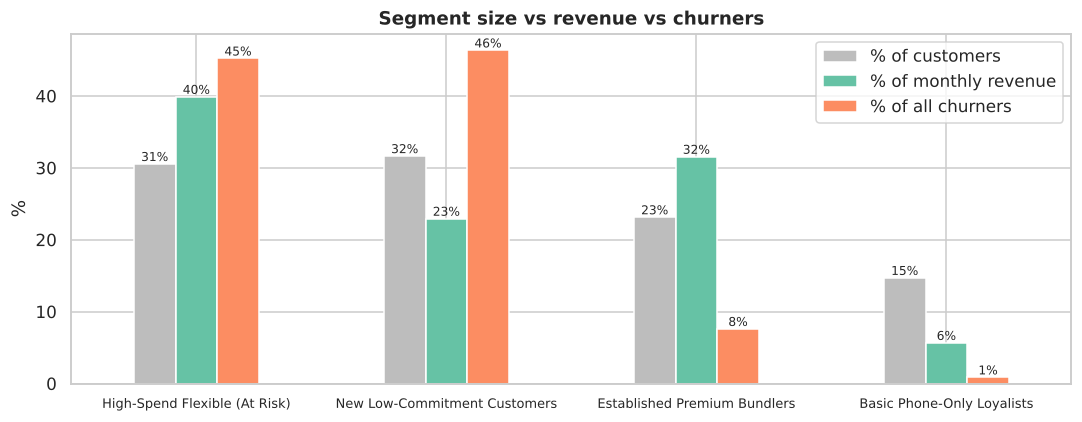

,% of customers,% of monthly revenue,% of all churners,Monthly revenue lost to churn ($)
segment,,,,
High-Spend Flexible (At Risk),30.5,39.9,45.2,75846.8
New Low-Commitment Customers,31.6,22.9,46.3,49014.1
Established Premium Bundlers,23.1,31.5,7.6,13787.2
Basic Phone-Only Loyalists,14.7,5.7,0.9,482.8


In [47]:
# --- 5.3 Share of total monthly revenue and of churners by segment ---------------------
share = pd.DataFrame({
    "% of customers": df["segment"].value_counts(normalize=True) * 100,
    "% of monthly revenue": df.groupby("segment")["MonthlyCharges"].sum() / df["MonthlyCharges"].sum() * 100,
    "% of all churners": df[df.Churn_flag == 1]["segment"].value_counts(normalize=True) * 100,
    "Monthly revenue lost to churn ($)": df[df.Churn_flag == 1].groupby("segment")["MonthlyCharges"].sum(),
}).loc[seg_order]
fig, ax = plt.subplots(figsize=(10, 4))
share[["% of customers", "% of monthly revenue", "% of all churners"]].plot.bar(ax=ax, color=["#bdbdbd", "#66c2a5", "#fc8d62"])
for c_ in ax.containers:
    ax.bar_label(c_, fmt="%.0f%%", fontsize=8)
ax.set(title="Segment size vs revenue vs churners", ylabel="%", xlabel="")
ax.tick_params(axis="x", rotation=0, labelsize=8.5)
plt.tight_layout(); plt.savefig("figures/segment_revenue_churn_share.png", bbox_inches="tight"); plt.show()
share.round(1)

## 6. Hierarchical Clustering (comparison)

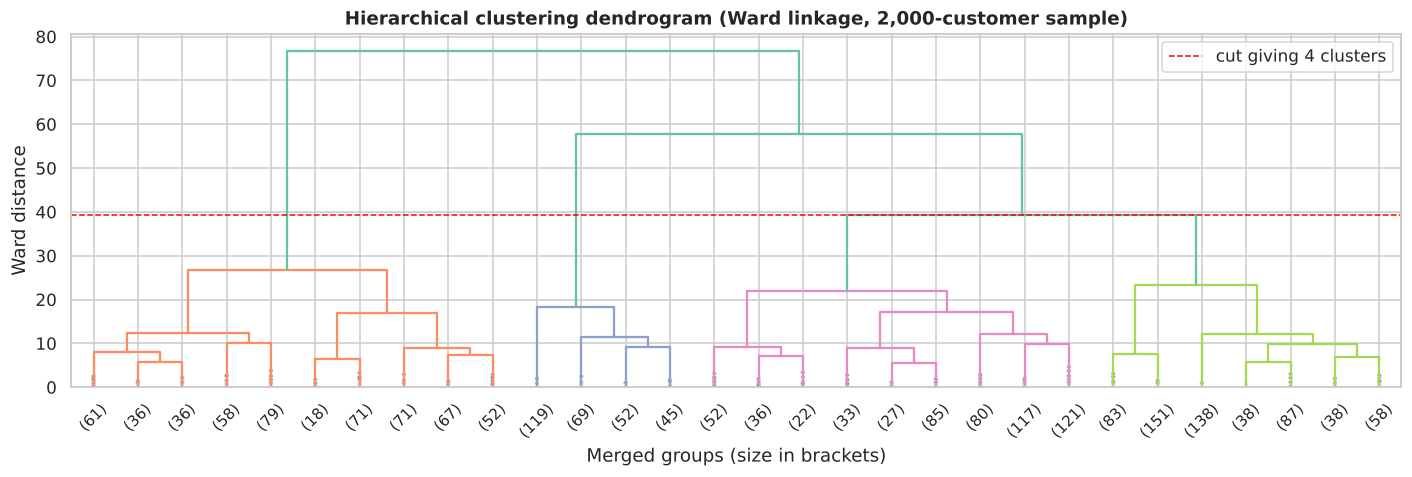

Hierarchical (Ward) silhouette: 0.323  vs  K-Means: 0.360
Adjusted Rand Index between K-Means and hierarchical clusters: 0.416 (1 = identical, 0 = random)


Hierarchical cluster,0,1,2,3
K-Means segment,,,,
Basic Phone-Only Loyalists,2,145,888,0
Established Premium Bundlers,0,820,0,809
High-Spend Flexible (At Risk),1187,964,0,0
New Low-Commitment Customers,2034,75,119,0


In [48]:
# Ward-linkage agglomerative clustering on a random sample (the full linkage matrix is O(n²) in memory)
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(Z), 2000, replace=False)
Zs = Z[sample_idx]
link = linkage(Zs, method="ward")

fig, ax = plt.subplots(figsize=(13, 4.5))
dendrogram(link, truncate_mode="lastp", p=30, ax=ax, color_threshold=link[-(K - 1), 2], show_contracted=True)
ax.axhline(link[-(K - 1), 2], color="red", ls="--", lw=1, label=f"cut giving {K} clusters")
ax.set(title="Hierarchical clustering dendrogram (Ward linkage, 2,000-customer sample)",
       xlabel="Merged groups (size in brackets)", ylabel="Ward distance")
ax.legend()
plt.tight_layout(); plt.savefig("figures/hierarchical_dendrogram.png", bbox_inches="tight"); plt.show()

# Compare with K-Means on the full data using Agglomerative clustering
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)
ari = adjusted_rand_score(kmeans.labels_, agg.labels_)
print(f"Hierarchical (Ward) silhouette: {silhouette_score(Z, agg.labels_):.3f}  vs  K-Means: {silhouette_score(Z, kmeans.labels_):.3f}")
print(f"Adjusted Rand Index between K-Means and hierarchical clusters: {ari:.3f} (1 = identical, 0 = random)")
pd.crosstab(df["segment"], agg.labels_, rownames=["K-Means segment"], colnames=["Hierarchical cluster"])

**Comparison.** Ward hierarchical clustering gives a slightly lower silhouette (0.32 vs 0.36) and **agrees only partially** with K-Means
(Adjusted Rand Index ≈ 0.42). The cross-tabulation shows where they agree and differ:
- **They agree** on the two clearest groups: *Basic Phone-Only Loyalists* and *New Low-Commitment Customers* map mostly onto single hierarchical clusters.
- **They differ** on the high-spend customers. Hierarchical clustering splits *High-Spend Flexible* and *Established Premium Bundlers*
  along a different line and mixes parts of the two.

So the "new" and "phone-only" segments are robust, while the boundary between the two high-spend groups depends on the method.
K-Means is kept as the final model because it has the higher silhouette, scales to the full dataset, and its split by **contract
commitment** gives a sharper difference in churn (39% vs 9%) than the hierarchical split does, which is more useful for action.

### The identified segments
The exact sizes and percentages are in the profile table above.
- **New Low-Commitment Customers:** very short tenure, month-to-month contracts, few add-ons, low-to-medium bills, frequent electronic-check
  payment. **Very high churn.** These customers leave before they become attached to the service.
- **High-Spend Flexible (At Risk):** mid tenure, **high monthly bills** (mostly fiber optic) but still on month-to-month contracts.
  **Very high churn, and the most revenue lost.** They pay premium prices without committing, which makes them the most valuable group to retain.
- **Established Premium Bundlers:** long tenure, one- or two-year contracts, many add-ons, high bills. **Low churn.** The company's most valuable loyal base.
- **Basic Phone-Only Loyalists:** mostly no internet service, very low bills, long contracts. **Almost no churn.** Stable but low revenue; an upsell opportunity.

---
# Part C – Association Rule Mining

**Goal:** find combinations of customer attributes and services that frequently occur together, especially combinations
linked to **churn**, to **staying**, and to **buying other services** (cross-selling).

**Approach:** each customer is treated as a "transaction" (a shopping basket) whose "items" are their attribute values, for example
`Contract=Month-to-month` or `TechSupport=No`. Numeric columns are put into bins so they can become items.

**Key measures:**
- **Support:** share of all customers who have the whole itemset (how common the pattern is).
- **Confidence:** P(consequent | antecedent), how often the rule holds.
- **Lift:** confidence ÷ support of the consequent. A lift above 1 means the items occur together more often than chance would predict.

## 7. Building Transactions and Mining Frequent Itemsets

Transactions: 7,043 customers x 40 possible items


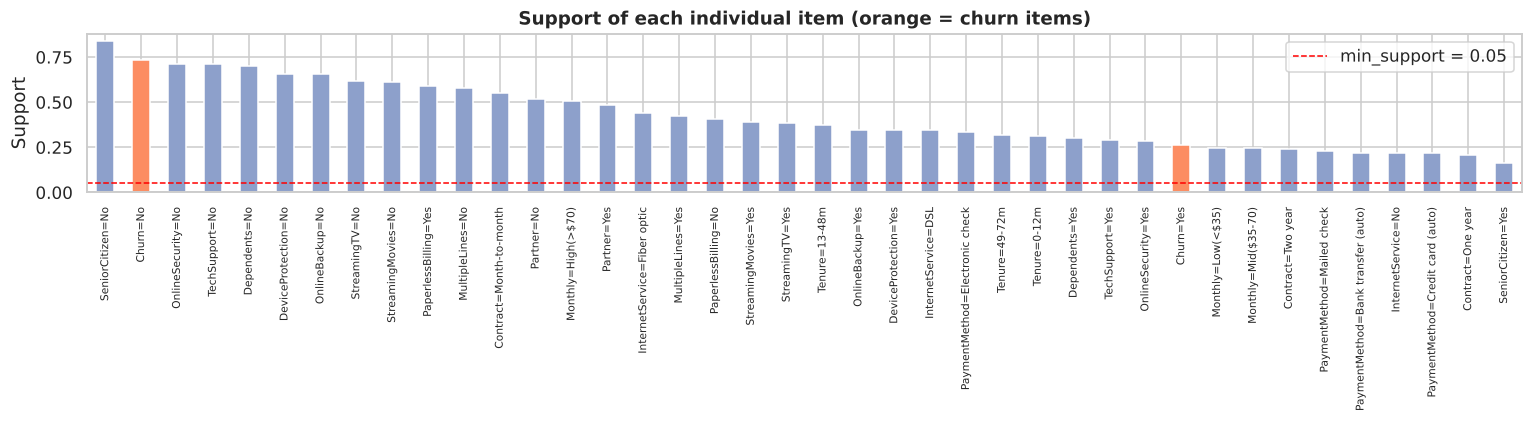

In [49]:
# --- Convert each customer into a set of boolean "items" ---------------------------
T = pd.DataFrame(index=df.index)
yes_no_cols = ["SeniorCitizen", "Partner", "Dependents", "MultipleLines", "OnlineSecurity", "OnlineBackup",
               "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling"]
for c in yes_no_cols:
    T[f"{c}=Yes"] = df[c] == "Yes"
    T[f"{c}=No"] = df[c] == "No"
for c in ["InternetService", "Contract", "PaymentMethod", "Churn"]:
    for v in sorted(df[c].unique()):
        T[f"{c}={v}"] = df[c] == v

# Discretise numeric attributes into interpretable bins
T["Tenure=0-12m"] = df["tenure"] <= 12
T["Tenure=13-48m"] = df["tenure"].between(13, 48)
T["Tenure=49-72m"] = df["tenure"] > 48
T["Monthly=Low(<$35)"] = df["MonthlyCharges"] < 35
T["Monthly=Mid($35-70)"] = df["MonthlyCharges"].between(35, 70)
T["Monthly=High(>$70)"] = df["MonthlyCharges"] > 70

# PhoneService (90% Yes) is left out: an item almost everyone has produces many trivial rules with no information.
print(f"Transactions: {T.shape[0]:,} customers x {T.shape[1]} possible items")
item_support = T.mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 4))
item_support.plot.bar(ax=ax, color=["#fc8d62" if i.startswith("Churn") else "#8da0cb" for i in item_support.index])
ax.axhline(0.05, color="red", ls="--", lw=1, label="min_support = 0.05")
ax.set(title="Support of each individual item (orange = churn items)", ylabel="Support")
ax.tick_params(axis="x", labelsize=7); ax.legend()
plt.tight_layout(); plt.savefig("figures/item_support.png", bbox_inches="tight"); plt.show()

In [50]:
# --- Apriori vs FP-Growth -------------------------------------------------------------
# min_support = 0.05: a pattern must cover at least ~350 customers to be considered,
# common enough to matter for business decisions. max_len = 4 keeps rules readable.
MIN_SUPPORT, MAX_LEN = 0.05, 4

t0 = time.time(); freq_ap = apriori(T, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN); t_ap = time.time() - t0
t0 = time.time(); freq_fp = fpgrowth(T, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN); t_fp = time.time() - t0

same = set(map(frozenset, freq_ap["itemsets"])) == set(map(frozenset, freq_fp["itemsets"]))
print(f"Apriori  : {len(freq_ap):,} frequent itemsets in {t_ap:.2f} s")
print(f"FP-Growth: {len(freq_fp):,} frequent itemsets in {t_fp:.2f} s")
print(f"Both algorithms found identical itemsets: {same}")
freq = freq_ap
freq["length"] = freq["itemsets"].apply(len)
freq.groupby("length").size().to_frame("number of frequent itemsets").T

Apriori  : 20,819 frequent itemsets in 0.83 s
FP-Growth: 20,819 frequent itemsets in 3.47 s
Both algorithms found identical itemsets: True


length,1,2,3,4
number of frequent itemsets,40,679,4989,15111


Apriori and FP-Growth return **exactly the same itemsets**, as they should, since both are exact algorithms. They differ only in speed:
Apriori generates and tests candidate itemsets level by level, while FP-Growth compresses the data into a prefix tree and avoids
candidate generation. The Apriori results are used below.

## 8. Generating and Filtering Rules

In [51]:
rules = association_rules(freq, metric="confidence", min_threshold=0.5)
rules["antecedent_str"] = rules["antecedents"].apply(lambda s: " & ".join(sorted(s)))
rules["consequent_str"] = rules["consequents"].apply(lambda s: " & ".join(sorted(s)))
rules["n_ante"] = rules["antecedents"].apply(len)
print(f"Rules with confidence >= 0.5: {len(rules):,}")

def prune_redundant(r, min_gain=0.02):
    """Remove a rule if a simpler rule (antecedent is a strict subset, same consequent) already reaches
    nearly the same confidence. Keeps only rules whose extra conditions add real predictive value."""
    r = r.sort_values("n_ante")
    keep = []
    for i, row in r.iterrows():
        simpler = r[(r["consequents"] == row["consequents"]) & (r["n_ante"] < row["n_ante"]) &
                    (r["antecedents"].apply(lambda a: a < row["antecedents"]))]
        if len(simpler) == 0 or row["confidence"] - simpler["confidence"].max() >= min_gain:
            keep.append(i)
    return r.loc[keep]

show_cols = ["antecedent_str", "consequent_str", "support", "confidence", "lift"]

Rules with confidence >= 0.5: 73,243


### 8.1 Rules that predict churn

In [52]:
churn_rules = rules[(rules["consequent_str"] == "Churn=Yes") & (rules["lift"] > 1.5)]
print(f"Churn rules with lift > 1.5 before pruning: {len(churn_rules)}")
churn_rules = prune_redundant(churn_rules).sort_values(["lift", "support"], ascending=False)
print(f"After removing redundant rules: {len(churn_rules)}")
churn_rules[show_cols].head(15).round(3).reset_index(drop=True)

Churn rules with lift > 1.5 before pruning: 263


After removing redundant rules: 179


,antecedent_str,consequent_str,support,confidence,lift
0,InternetService=Fiber optic & PaperlessBilling=Yes & Tenure=0-12m,Churn=Yes,0.074,0.723,2.724
1,Monthly=High(>$70) & PaperlessBilling=Yes & Tenure=0-12m,Churn=Yes,0.069,0.713,2.686
2,Monthly=High(>$70) & OnlineSecurity=No & Tenure=0-12m,Churn=Yes,0.078,0.708,2.669
3,Monthly=High(>$70) & TechSupport=No & Tenure=0-12m,Churn=Yes,0.076,0.701,2.642
4,InternetService=Fiber optic & Tenure=0-12m,Churn=Yes,0.092,0.699,2.633
5,Monthly=High(>$70) & Tenure=0-12m,Churn=Yes,0.084,0.679,2.558
6,PaperlessBilling=Yes & PaymentMethod=Electronic check & Tenure=0-12m,Churn=Yes,0.068,0.671,2.528
7,OnlineSecurity=No & PaymentMethod=Electronic check & Tenure=0-12m,Churn=Yes,0.080,0.643,2.422
8,PaymentMethod=Electronic check & Tenure=0-12m,Churn=Yes,0.086,0.620,2.335
9,Contract=Month-to-month & InternetService=Fiber optic & PaymentMethod=Electronic check,Churn=Yes,0.112,0.604,2.275


### 8.2 Rules that predict staying (retention patterns)

In [53]:
stay_rules = rules[(rules["consequent_str"] == "Churn=No") & (rules["confidence"] >= 0.95)]
stay_rules = prune_redundant(stay_rules, min_gain=0.01).sort_values(["support", "confidence"], ascending=False)
print(f"Retention rules (confidence >= 95%, non-redundant): {len(stay_rules)}")
stay_rules[show_cols].head(10).round(3).reset_index(drop=True)

Retention rules (confidence >= 95%, non-redundant): 69


,antecedent_str,consequent_str,support,confidence,lift
0,Contract=Two year,Churn=No,0.234,0.972,1.323
1,StreamingTV=No & Tenure=49-72m,Churn=No,0.137,0.955,1.301
2,StreamingMovies=No & Tenure=49-72m,Churn=No,0.134,0.953,1.298
3,Contract=Two year & StreamingTV=No,Churn=No,0.131,0.987,1.344
4,Contract=Two year & StreamingMovies=No,Churn=No,0.130,0.985,1.341
5,Contract=Two year & PaperlessBilling=No,Churn=No,0.127,0.984,1.339
6,Contract=Two year & DeviceProtection=No,Churn=No,0.122,0.984,1.339
7,Contract=Two year & MultipleLines=No,Churn=No,0.115,0.984,1.340
8,Contract=One year & StreamingMovies=No,Churn=No,0.110,0.953,1.297
9,InternetService=DSL & Tenure=49-72m,Churn=No,0.107,0.957,1.302


### 8.3 Cross-sell rules between services

In [54]:
service_items = [f"{c}=Yes" for c in ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                                      "TechSupport", "StreamingTV", "StreamingMovies"]] + ["InternetService=Fiber optic"]
is_service_set = lambda s: all(i in service_items for i in s)
xsell = rules[rules["antecedents"].apply(is_service_set) & rules["consequents"].apply(is_service_set)
              & (rules["consequents"].apply(len) == 1) & (rules["lift"] > 1.3)]
xsell = prune_redundant(xsell).sort_values("lift", ascending=False)
print(f"Cross-sell rules (service -> service, lift > 1.3): {len(xsell)}")
xsell[show_cols].head(12).round(3).reset_index(drop=True)

Cross-sell rules (service -> service, lift > 1.3): 236


,antecedent_str,consequent_str,support,confidence,lift
0,DeviceProtection=Yes & OnlineSecurity=Yes & StreamingMovies=Yes,TechSupport=Yes,0.073,0.699,2.407
1,DeviceProtection=Yes & OnlineSecurity=Yes & StreamingTV=Yes,TechSupport=Yes,0.071,0.695,2.395
2,OnlineBackup=Yes & OnlineSecurity=Yes & StreamingTV=Yes,TechSupport=Yes,0.062,0.679,2.338
3,DeviceProtection=Yes & OnlineBackup=Yes & OnlineSecurity=Yes,TechSupport=Yes,0.067,0.678,2.337
4,OnlineBackup=Yes & OnlineSecurity=Yes & StreamingMovies=Yes,TechSupport=Yes,0.062,0.676,2.331
5,DeviceProtection=Yes & MultipleLines=Yes & OnlineSecurity=Yes,TechSupport=Yes,0.060,0.669,2.304
6,OnlineSecurity=Yes & StreamingMovies=Yes & StreamingTV=Yes,TechSupport=Yes,0.072,0.657,2.263
7,DeviceProtection=Yes & OnlineBackup=Yes & TechSupport=Yes,OnlineSecurity=Yes,0.067,0.647,2.258
8,OnlineSecurity=Yes & StreamingMovies=Yes & TechSupport=Yes,DeviceProtection=Yes,0.073,0.769,2.237
9,OnlineSecurity=Yes & StreamingTV=Yes & TechSupport=Yes,DeviceProtection=Yes,0.071,0.763,2.220


### 8.4 Visualising the rules

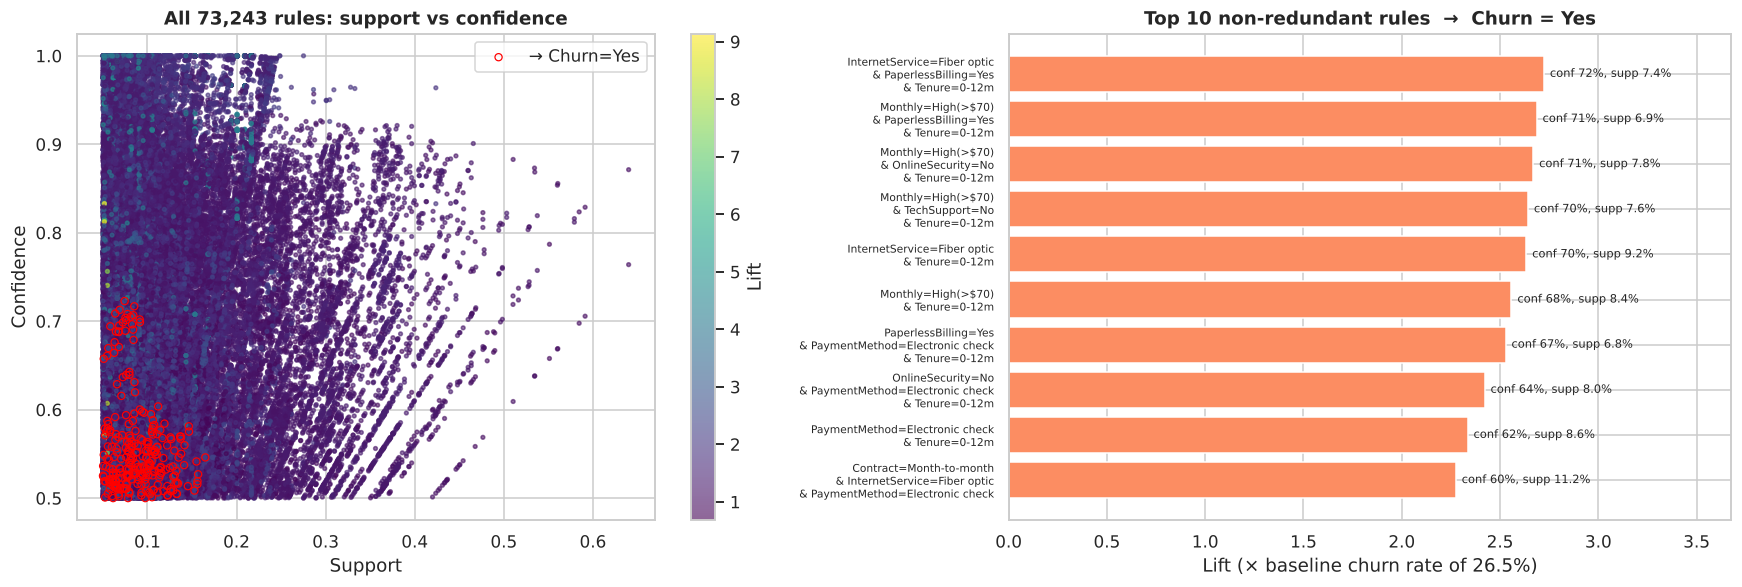

In [55]:
# --- Support vs confidence for all rules, coloured by lift ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sc = axes[0].scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=6, alpha=.6)
plt.colorbar(sc, ax=axes[0], label="Lift")
cr = rules[rules["consequent_str"] == "Churn=Yes"]
axes[0].scatter(cr["support"], cr["confidence"], facecolors="none", edgecolors="red", s=22, lw=.8, label="→ Churn=Yes")
axes[0].set(title=f"All {len(rules):,} rules: support vs confidence", xlabel="Support", ylabel="Confidence")
axes[0].legend()

# --- Top non-redundant churn rules by lift ------------------------------------------
top_cr = churn_rules.head(10).iloc[::-1]
bars = axes[1].barh(top_cr["antecedent_str"].str.replace(" & ", "\n& ", regex=False), top_cr["lift"], color="#fc8d62")
for b, (conf, sup) in zip(bars, zip(top_cr["confidence"], top_cr["support"])):
    axes[1].text(b.get_width() + 0.03, b.get_y() + b.get_height() / 2, f"conf {conf:.0%}, supp {sup:.1%}",
                 va="center", fontsize=7.5)
axes[1].set(title="Top 10 non-redundant rules  →  Churn = Yes", xlabel="Lift (× baseline churn rate of 26.5%)",
            xlim=(0, top_cr["lift"].max() * 1.35))
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig("figures/association_rules_overview.png", bbox_inches="tight"); plt.show()

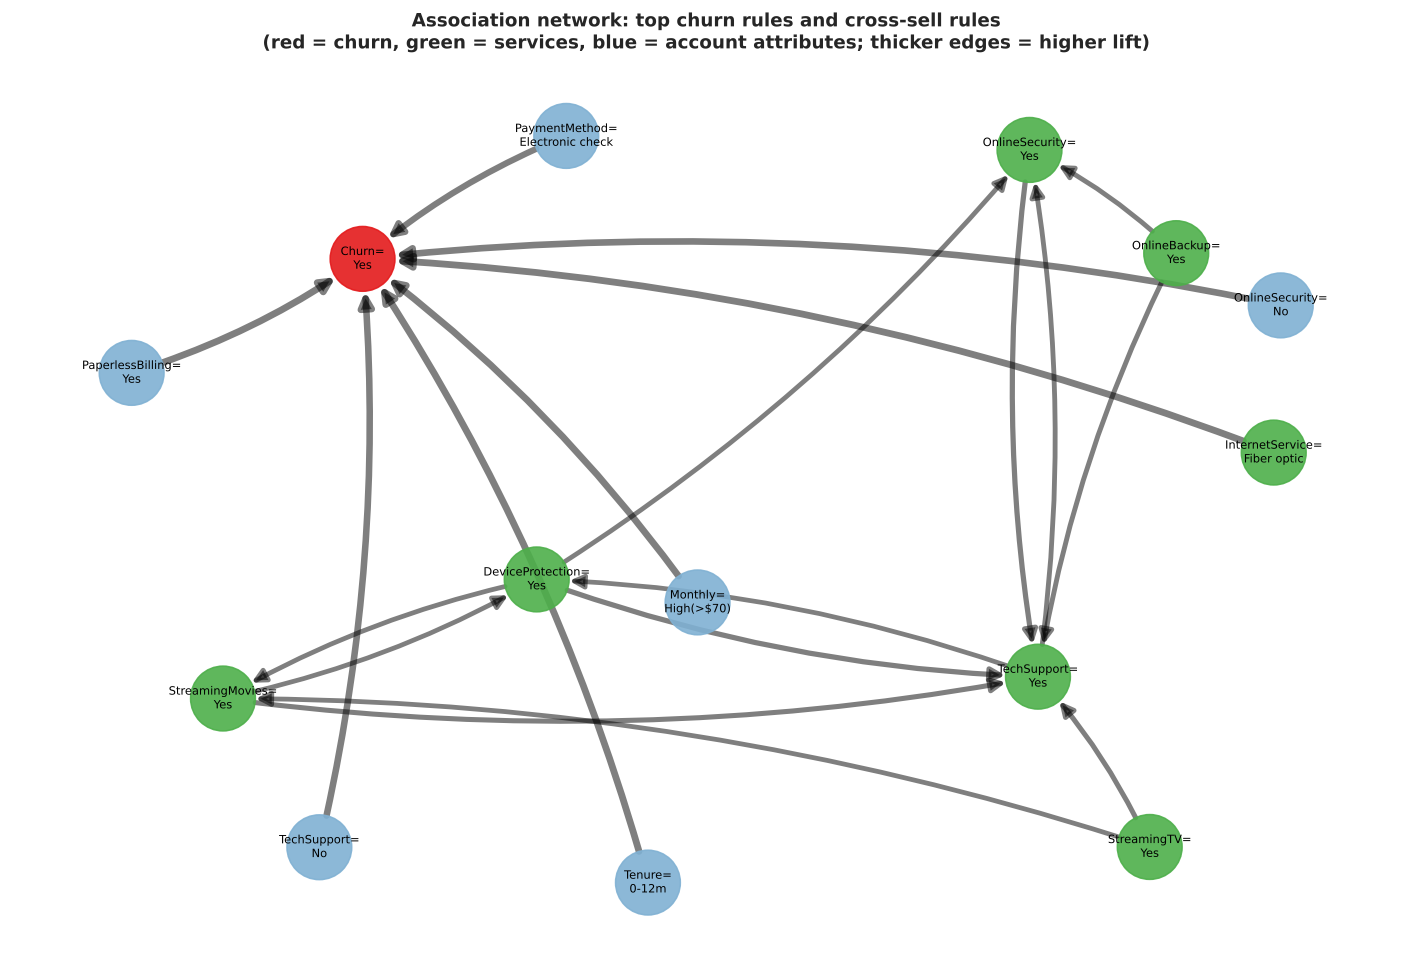

In [56]:
# --- Network graph of the strongest rules involving churn and services ---------------
G = nx.DiGraph()
net_rules = pd.concat([churn_rules.head(8), xsell[xsell["n_ante"] <= 2].head(8)])
for _, r in net_rules.iterrows():
    for a in r["antecedents"]:
        for c in r["consequents"]:
            if G.has_edge(a, c):
                G[a][c]["lift"] = max(G[a][c]["lift"], r["lift"])
            else:
                G.add_edge(a, c, lift=r["lift"])

fig, ax = plt.subplots(figsize=(13, 9))
pos = nx.spring_layout(G, k=1.6, seed=7)
node_col = ["#e41a1c" if n.startswith("Churn") else "#4daf4a" if n in service_items else "#80b1d3" for n in G.nodes]
widths = [1 + 2 * (G[u][v]["lift"] - 1) for u, v in G.edges]
nx.draw_networkx_nodes(G, pos, node_color=node_col, node_size=1800, alpha=.9, ax=ax)
nx.draw_networkx_edges(G, pos, width=widths, alpha=.5, arrowsize=18, ax=ax, connectionstyle="arc3,rad=0.08",
                       node_size=1800)
nx.draw_networkx_labels(G, pos, labels={n: n.replace("=", "=\n") for n in G.nodes}, font_size=7.5, ax=ax)
ax.set_title("Association network: top churn rules and cross-sell rules\n"
             "(red = churn, green = services, blue = account attributes; thicker edges = higher lift)")
ax.axis("off")
plt.tight_layout(); plt.savefig("figures/association_network.png", bbox_inches="tight"); plt.show()

## 9. Applying the Patterns in the Real World

| Pattern discovered | Real-world application |
|---|---|
| **{Fiber optic, tenure ≤ 12 months, …} → Churn** (about 70% confidence, lift ≈ 2.6–2.7) | **Early-life retention programme:** automatically flag new fiber customers for an onboarding call, a first-year loyalty discount, or a service-quality check during months 1–12. |
| **{…, OnlineSecurity = No / TechSupport = No} → Churn** | **Bundle protection services into fiber plans** (free 3-month trial of TechSupport/OnlineSecurity), since customers with these add-ons churn about half as often. |
| **{Electronic check, Month-to-month, …} → Churn** | **Nudge customers to automatic payments** (small bill credit). Combined with the classification results, this is a cheap, targeted intervention. |
| **{Two-year contract} → Stay** (97% confidence; up to 99% with other conditions) | **Contract-upgrade campaigns:** offer at-risk month-to-month customers a discounted 1–2 year contract; contracts almost guarantee retention. |
| **{StreamingTV} → {StreamingMovies}** (72% confidence, lift 1.85, 28% of customers) and **{OnlineSecurity, DeviceProtection} → TechSupport** (64%, lift 2.2) | **Cross-sell recommendations:** a "customers who have X also have Y" engine for the call centre and web portal, and natural **service bundles** (an entertainment pack, a protection pack). |
| Rules as simple IF–THEN statements | Business teams can apply them **without a machine-learning system**, for example as filters in the CRM to build campaign target lists. |

### Summary of Deliverable 3 results

In [57]:
best_f1 = results["F1"].idxmax(); best_auc = results["ROC-AUC"].idxmax()
print("CLASSIFICATION")
print(results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].round(3).to_string())
print(f"\nBest F1: {best_f1} ({results.loc[best_f1, 'F1']:.3f}); best ROC-AUC: {best_auc} ({results.loc[best_auc, 'ROC-AUC']:.3f})")
print(f"Tuned tree parameters: {grid.best_params_}")
print("\nCLUSTERING (K-Means, k = 4)")
print(profile[["customers", "tenure", "monthly_charges", "num_addons", "pct_month_to_month", "churn_rate"]].round(1).to_string())
print(f"K-Means vs hierarchical ARI = {ari:.3f}")
print("\nASSOCIATION RULES")
print(f"{len(freq):,} frequent itemsets, {len(rules):,} rules; {len(churn_rules)} non-redundant churn rules, "
      f"{len(stay_rules)} retention rules, {len(xsell)} cross-sell rules")
print("Strongest churn rule:", churn_rules.iloc[0]["antecedent_str"],
      f"-> Churn=Yes (conf {churn_rules.iloc[0]['confidence']:.1%}, lift {churn_rules.iloc[0]['lift']:.2f})")

CLASSIFICATION
                         Accuracy  Precision  Recall     F1  ROC-AUC
Decision Tree (default)     0.730      0.492   0.505  0.499    0.658
Decision Tree (tuned)       0.746      0.514   0.783  0.621    0.816
k-NN                        0.776      0.580   0.570  0.575    0.819
Naive Bayes                 0.732      0.497   0.778  0.606    0.821
SVM (RBF)                   0.742      0.509   0.757  0.609    0.818
Logistic Regression         0.739      0.505   0.781  0.613    0.841

Best F1: Decision Tree (tuned) (0.621); best ROC-AUC: Logistic Regression (0.841)
Tuned tree parameters: {'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}

CLUSTERING (K-Means, k = 4)
                               customers  tenure  monthly_charges  num_addons  pct_month_to_month  churn_rate
cluster_id                                                                                                   
High-Spend Flexible (At Risk)       2151

---
# Part 4 – Ethical Review, Consolidated Results and Recommendations (Deliverable 4)

## 4.1 Fairness audit of the tuned decision tree
The tuned tree never receives gender or age as an explicit rule, but it could still treat groups differently through proxy variables.
The audit compares **recall** (share of actual churners flagged) and the **false positive rate** (share of loyal customers flagged) across demographic groups on the held-out test set.

Features used by the tuned tree: ['Contract_Two year', 'InternetService_Fiber optic', 'MonthlyCharges', 'contract_months', 'tenure']


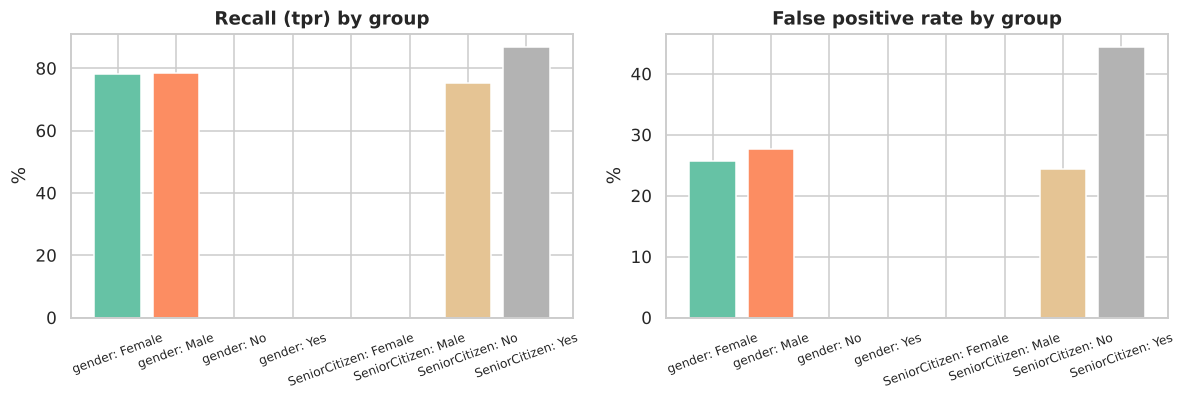

In [58]:
# --- 4.1 Fairness audit on the test set ---------------------------------------------
test_demo = df.loc[X_test.index, ["gender", "SeniorCitizen"]].copy()
test_demo["y"] = y_test
test_demo["pred"] = preds["Decision Tree (tuned)"]

def group_rates(frame, by):
    rows = {}
    for g, sub in frame.groupby(by):
        pos, neg = sub[sub.y == 1], sub[sub.y == 0]
        rows[g] = {"customers": len(sub), "actual churn rate": sub.y.mean(), "flag rate": sub.pred.mean(),
                   "recall (TPR)": pos.pred.mean(), "false positive rate": neg.pred.mean()}
    return pd.DataFrame(rows).T

audit = pd.concat({"gender": group_rates(test_demo, "gender"),
                   "SeniorCitizen": group_rates(test_demo, "SeniorCitizen")})
print("Features used by the tuned tree:", sorted(set(X.columns[best_tree.tree_.feature[best_tree.tree_.feature >= 0]])))
display(audit.style.format({"actual churn rate": "{:.1%}", "flag rate": "{:.1%}", "recall (TPR)": "{:.1%}", "false positive rate": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric in zip(axes, ["recall (TPR)", "false positive rate"]):
    plot_df = audit[metric].unstack(0).T.stack().reset_index()
    plot_df.columns = ["attribute", "group", metric]
    plot_df["label"] = plot_df["attribute"] + ": " + plot_df["group"].astype(str)
    ax.bar(plot_df["label"], plot_df[metric] * 100, color=sns.color_palette("Set2", len(plot_df)))
    ax.set(title=metric.capitalize() + " by group", ylabel="%"); ax.tick_params(axis="x", labelsize=8, rotation=20)
plt.tight_layout(); plt.savefig("figures/fairness_audit.png", bbox_inches="tight"); plt.show()

**Reading the audit:** gender shows essentially no disparity. For senior citizens the model flags a much larger share of *loyal* customers (higher false positive rate),
even though age is not an input, because seniors hold more month-to-month fiber plans, which act as **proxy variables**.
Retention actions should therefore be framed as benefits (discounts, contract incentives, extra support) rather than penalties, and flag rates by group should be monitored after deployment.

## 4.2 Consolidated results across all techniques

In [59]:
# --- 4.2 One summary of every technique ----------------------------------------------
print("REGRESSION (TotalCharges, held-out test set)")
print(summary[["Test R²", "Test RMSE", "Test MAE"]].round(4).to_string())
print("\nCLASSIFICATION (churn, held-out test set)")
print(results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].round(3).to_string())
print("\nCLUSTERING (K-Means, k = 4)")
print(profile[["customers", "tenure", "monthly_charges", "pct_month_to_month", "churn_rate"]].round(1).to_string())
top2 = profile.sort_values("churn_rate", ascending=False).head(2)
churners_share = df[df.segment.isin(top2.index)].Churn_flag.sum() / df.Churn_flag.sum()
print(f"Two highest-churn segments hold {churners_share:.1%} of all churners")
print("\nASSOCIATION RULES")
print(f"{len(freq):,} itemsets, {len(rules):,} rules -> {len(churn_rules)} churn / {len(stay_rules)} retention / {len(xsell)} cross-sell (non-redundant)")

# Save the headline tables for the report
summary.to_csv("regression_results.csv"); results.to_csv("classification_results.csv"); profile.to_csv("cluster_profiles.csv")
audit.to_csv("fairness_audit.csv"); churn_rules[show_cols].to_csv("churn_rules.csv", index=False)

REGRESSION (TotalCharges, held-out test set)
                          Test R²  Test RMSE  Test MAE
Lasso (engineered)         0.9986    85.0037   54.2019
Linear (engineered)        0.9986    85.3166   54.5319
Ridge (engineered)         0.9986    85.3196   54.5445
Random Forest (baseline)   0.9953   155.7184   94.6677
Linear (baseline)          0.9043   705.4355  571.2020

CLASSIFICATION (churn, held-out test set)
                         Accuracy  Precision  Recall     F1  ROC-AUC
Decision Tree (default)     0.730      0.492   0.505  0.499    0.658
Decision Tree (tuned)       0.746      0.514   0.783  0.621    0.816
k-NN                        0.776      0.580   0.570  0.575    0.819
Naive Bayes                 0.732      0.497   0.778  0.606    0.821
SVM (RBF)                   0.742      0.509   0.757  0.609    0.818
Logistic Regression         0.739      0.505   0.781  0.613    0.841

CLUSTERING (K-Means, k = 4)
                               customers  tenure  monthly_charges  pct

## 4.3 Key insights and recommendations
**Convergent finding:** exploratory analysis, the tuned decision tree, the segmentation and the association rules all point to the same churn drivers:
the **first year** of the relationship, **no long-term contract**, **fiber-optic** service, **electronic-check** payment, and **missing protection services**.

| # | Recommendation | Evidence from this notebook |
|---|---|---|
| 1 | Early-life retention program for new customers, especially fiber | Tree's riskiest leaf, New Low-Commitment segment, top churn rules |
| 2 | Contract upgrade incentives for High-Spend Flexible customers | Largest monthly revenue lost to churn; two-year contracts retain 97% |
| 3 | Bundle online security and technical support into fiber plans | Customers without them churn about twice as often; cross-sell rules |
| 4 | Small bill credit for automatic payment | Electronic check appears in the strongest churn rules |
| 5 | Put the tree and top rules in the CRM as campaign filters and cross-sell prompts | Interpretable depth-3 tree; 236 cross-sell rules |

**Ethics and limitations:** the data are a fictional single-period sample, so results must be re-validated on real provider data before use.
A real deployment needs consent, access controls, data minimisation and CCPA compliance, plus ongoing fairness monitoring with human review.
Future work: survival analysis for time-to-churn, gradient-boosted ensembles and cost-sensitive thresholds.